# W2 요인 분리 진단 — 180초, stress 도착률 0.2/s

설정: `configs/week7_180s_stress02.json`  |  결과: `results/w2_factorial_180s_stress02_review_20261027`

이 노트북은 해당 설정의 **225회 결과만** 읽습니다. 기본 W0와 네 가지 W2 요인을 같은 seed에서 비교하며, 아래 1~8절은 원본 `week9_60s_stress02_review.ipynb`의 흐름을 따릅니다. 정책 구현과 기존 결과 파일은 변경하지 않았습니다.

이 노트북은 **기존 다섯 정책을 수정하지 않고** 같은 seed의 입력을 네 방식으로 나눠 비교한다. 위에서 아래로 실행하면 결과 생성부터 Peak 근처 이벤트 확인까지 볼 수 있다. 저장된 출력은 5개 seed, 2×·4×의 실제 실행 결과다.

| 조건 | 도착 시각 | 도구 대기 |
|---|---|---|
| `base` | 원래 도착 | 기본 대기 × 강도 |
| `burst` | 10초 구간의 앞 1초에 집중 | 기본 대기 × 강도 |
| `wait` | 원래 도착 | 짧음·긺 교대 × 강도 |
| `both` | 집중 도착 | 짧음·긺 교대 × 강도 |

**읽기 전 주의:** `wait`는 대기 패턴뿐 아니라 평균 대기시간도 바꾼다. 이 표는 분산만의 효과를 측정하지 않는다. Duration-Aware는 실제 미래 대기시간을 예측값으로 쓰는 Oracle 참고선이다. 처리 속도는 실측 전 설정값이다.

## 1. 동일 설정으로 결과 준비

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'kvbench').exists():
    ROOT = ROOT.parent
assert (ROOT / 'kvbench').exists(), '노트북을 프로젝트 루트 또는 notebooks/에서 실행하세요.'
sys.path.insert(0, str(ROOT))

from kvbench.experiment import W2_FACTORIAL_CONDITIONS, W2_FACTORIAL_POLICIES, run_w2_factorial

OUTPUT = ROOT / 'results/w2_factorial_180s_stress02_review_20261027'
if not OUTPUT.exists():
    run_w2_factorial(
        ROOT / 'configs/week7_180s_stress02.json',
        ROOT / 'configs/system_1080ti_llama3b.json',
        ROOT / 'configs/policies_week7.json',
        OUTPUT,
    )
manifest = json.loads((OUTPUT / 'experiment.json').read_text(encoding='utf-8'))
assert manifest['workload_config'] == json.loads((ROOT / 'configs/week7_180s_stress02.json').read_text(encoding='utf-8'))
assert manifest['workload_config']['duration_ms'] == 180000
assert manifest['experiment'] == 'w2_factorial_diagnostic'
assert manifest['policies'] == list(W2_FACTORIAL_POLICIES)
assert manifest['seeds'] == list(range(5))
assert [(x['load'], x['workload'], x['stress_level']) for x in manifest['conditions']] == list(W2_FACTORIAL_CONDITIONS)

summary = pd.read_csv(OUTPUT / 'summary.csv')
comparison = pd.read_csv(OUTPUT / 'comparison.csv')
slo = pd.read_csv(OUTPUT / 'slo_by_seed.csv')
print(f'실험: {len(summary)} runs | {summary.policy.nunique()} policies | {summary.load.nunique()} conditions | {summary.seed.nunique()} seeds')
print(f'결과 경로: {OUTPUT}')

실험: 225 runs | 5 policies | 9 conditions | 5 seeds
결과 경로: C:\Users\user\Desktop\kv-bench\results\w2_factorial_180s_stress02_review_20261027


## 2. 먼저 입력이 얼마나 달라졌는지

정책 결과를 보기 전에 도구 대기시간 자체를 확인한다. W1의 `base_2x`와 W2의 `both_2x`는 이름에 같은 2×가 있어도 평균 대기가 다르다.

In [2]:
condition_map = {label: (workload, level) for label, workload, level in W2_FACTORIAL_CONDITIONS}
input_rows = []
for label, (workload, level) in condition_map.items():
    waits = []
    for seed in range(5):
        trace = OUTPUT / 'traces' / f'{workload.lower()}_s{level}_seed{seed}.jsonl'
        frame = pd.read_json(trace, lines=True)
        waits.extend(frame.loc[frame.tool_duration_ms > 0, 'tool_duration_ms'].tolist())
    series = pd.Series(waits)
    input_rows.append({'condition': label, 'tool_calls': len(waits),
                       'mean_wait_s': series.mean() / 1000,
                       'median_wait_s': series.median() / 1000,
                       'p95_wait_s': series.quantile(0.95) / 1000})
input_table = pd.DataFrame(input_rows)
display(input_table.round(2))

,condition,tool_calls,mean_wait_s,median_wait_s,p95_wait_s
0,w0_1x,516,2.93,2.88,4.78
1,base_2x,516,5.85,5.77,9.56
2,burst_2x,516,5.85,5.77,9.56
3,wait_2x,516,11.31,2.23,36.99
4,both_2x,516,11.31,2.23,36.99
5,base_4x,516,11.70,11.53,19.12
6,burst_4x,516,11.70,11.53,19.12
7,wait_4x,516,22.61,4.46,73.98
8,both_4x,516,22.61,4.46,73.98


## 3. 기존 SLO와 실제 지표를 나란히 보기

SLO 통과 수는 **해당 정책의 동일 seed W0 대비 P95 TTFT 3배 이하**, 일반 요청 거절률 10% 이하, Peak KV 90% 이하를 모두 만족한 seed 수다. 옆의 절대 TTFT와 90% 초과 시간을 함께 읽는다. 90% 초과 시간은 모든 정책에서 같은 `[10초, 180초)` 구간으로 계산했다.

In [3]:
selected = comparison[comparison.load.isin(['both_2x', 'both_4x'])].copy()
selected['SLO 통과'] = (selected.all_slo_pass_rate_pct / 20).round().astype(int).astype(str) + '/5'
overview = selected[['load', 'policy', 'SLO 통과',
                     'normal_p95_ttft_ms_mean', 'peak_kv_occupancy_pct_mean',
                     'kv_above_90_ms_mean', 'recomputed_tokens_mean', 'transfer_bytes_mean']].copy()
overview.columns = ['조건', '정책', 'SLO 통과', 'P95 TTFT (ms)', 'Peak KV (%)',
                    '90% 초과 시간 (ms)', '재계산 토큰', '전송 바이트']
display(overview.round(1))

,조건,정책,SLO 통과,P95 TTFT (ms),Peak KV (%),90% 초과 시간 (ms),재계산 토큰,전송 바이트
4,both_2x,pin_all,0/5,24168.9,100.0,95234.0,0.0,0.000000e+00
8,both_4x,pin_all,0/5,29813.5,100.0,134519.4,0.0,0.000000e+00
13,both_2x,evict_recompute,4/5,811.4,84.5,98.4,361485.8,0.000000e+00
17,both_4x,evict_recompute,4/5,691.0,80.9,1.5,361485.8,0.000000e+00
22,both_2x,fixed_ttl,2/5,515.9,91.5,2269.4,162194.4,0.000000e+00
26,both_4x,fixed_ttl,2/5,554.2,89.6,2975.0,247832.0,0.000000e+00
31,both_2x,lru_offload,0/5,305.7,99.7,33878.8,0.0,1.456409e+10
35,both_4x,lru_offload,0/5,313.2,100.0,54494.3,0.0,2.440267e+10
40,both_2x,duration_aware,0/5,304.8,99.5,5457.8,0.0,3.407610e+10
44,both_4x,duration_aware,0/5,309.8,98.7,6103.9,0.0,3.987105e+10


**이 설정의 SLO 요약:** W0부터 일부 seed가 Peak KV 90%를 넘습니다. 원래 W2(`both`)에서 Evict/Recompute는 2x와 4x 모두 4/5, Fixed TTL은 모두 2/5, Duration-Aware·LRU Offload·Pin-All은 모두 0/5입니다. 60초 결과와 직접 비교할 때는 관측 기간이 3배라는 차이를 함께 보세요.

### 같은 seed에서 상대 기준과 절대 시간을 비교

아래 표의 `W0 P95`가 정책마다 다르다. 따라서 절대 TTFT가 더 낮아도 자기 W0 대비 3배를 넘으면 TTFT 기준에서는 실패할 수 있다.

In [4]:
seed_example = slo[(slo.load == 'both_4x') & (slo.seed == 0) &
                   (slo.policy.isin(['duration_aware', 'fixed_ttl', 'evict_recompute']))]
display(seed_example[['policy', 'w0_p95_ttft_ms', 'normal_p95_ttft_ms',
                      'ttft_ratio_vs_policy_w0', 'ttft_pass', 'occupancy_pass', 'all_pass']].round(2))

,policy,w0_p95_ttft_ms,normal_p95_ttft_ms,ttft_ratio_vs_policy_w0,ttft_pass,occupancy_pass,all_pass
85,evict_recompute,491.35,592.30,1.21,True,True,True
130,fixed_ttl,428.77,525.68,1.23,True,True,True
220,duration_aware,108.37,311.96,2.88,True,False,False


## 4. 버스트와 교대 대기의 영향

아래 그림은 **동일 강도 안에서** 기본·버스트·교대·둘 다를 비교한다. 위에서 확인한 대로 교대 규칙은 평균 대기도 바꾸므로, 선 사이의 차이를 순수한 변동성 효과라고 부르지 않는다.

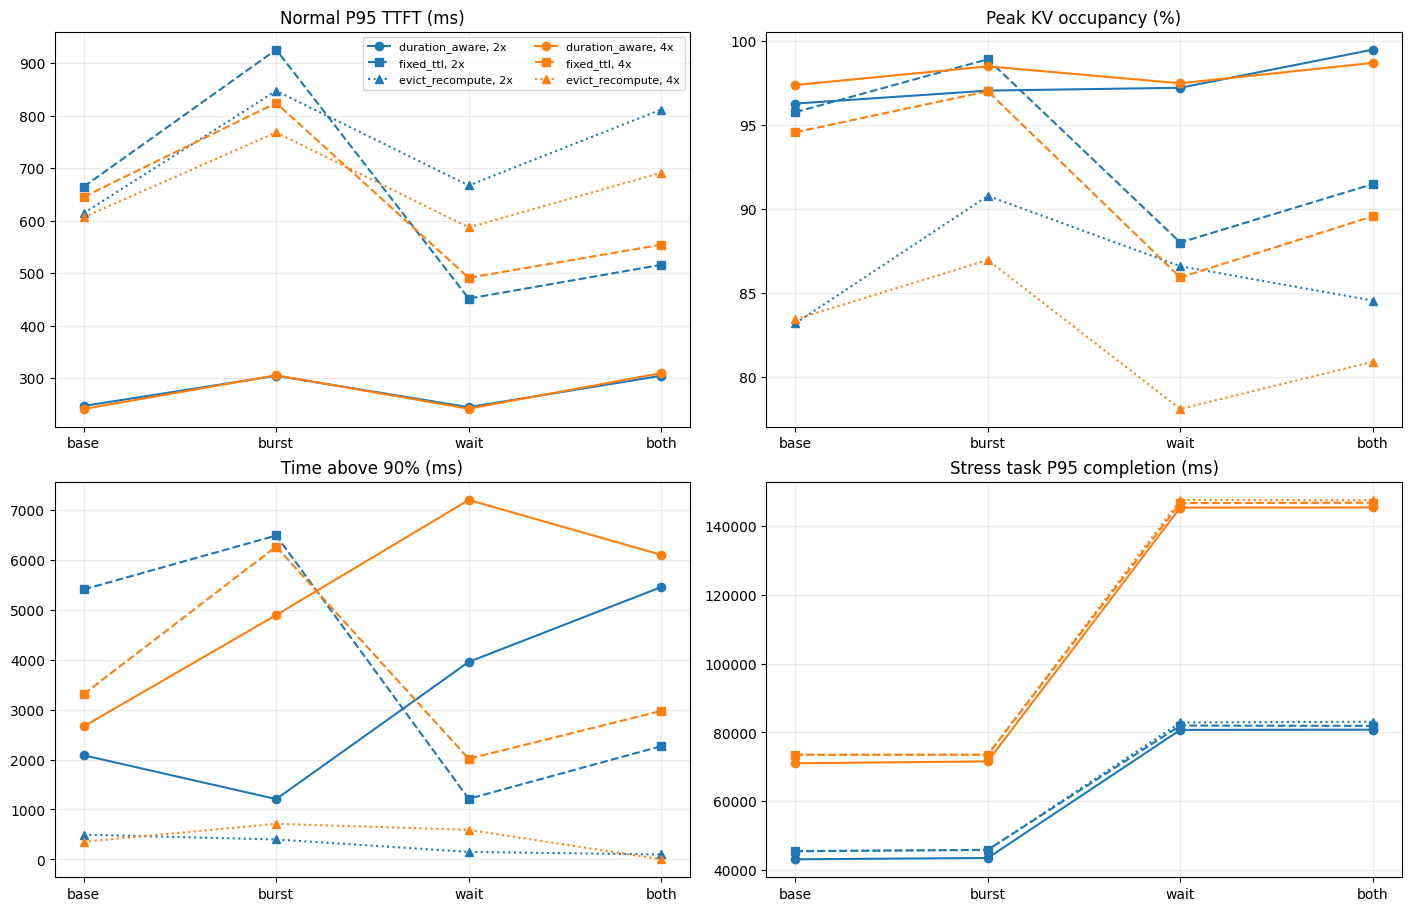

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
metrics = [
    ('normal_p95_ttft_ms_mean', 'Normal P95 TTFT (ms)'),
    ('peak_kv_occupancy_pct_mean', 'Peak KV occupancy (%)'),
    ('kv_above_90_ms_mean', 'Time above 90% (ms)'),
    ('stress_p95_completion_ms_mean', 'Stress task P95 completion (ms)'),
]
for level, color in [(2, 'tab:blue'), (4, 'tab:orange')]:
    labels = [f'{kind}_{level}x' for kind in ('base', 'burst', 'wait', 'both')]
    for policy, marker in [('duration_aware', 'o'), ('fixed_ttl', 's'), ('evict_recompute', '^')]:
        subset = comparison[(comparison.policy == policy)].set_index('load').reindex(labels)
        for ax, (metric, title) in zip(axes.flat, metrics):
            ax.plot(range(4), subset[metric], marker=marker, color=color,
                    linestyle='-' if policy == 'duration_aware' else '--' if policy == 'fixed_ttl' else ':',
                    label=f'{policy}, {level}x')
for ax, (_, title) in zip(axes.flat, metrics):
    ax.set_title(title)
    ax.set_xticks(range(4), ['base', 'burst', 'wait', 'both'])
    ax.grid(alpha=.25)
axes[0, 0].legend(fontsize=8, ncol=2)
plt.show()

## 5. Duration-Aware는 실제로 무엇을 선택했나?

현재 설정에서는 KEEP/OFFLOAD/EVICT 중 EVICT가 거의 또는 전혀 나타나지 않을 수 있다. 선택 횟수를 세어 3-way 판단이 실제로 평가되었는지 확인한다.

In [6]:
decision_rows = []
for load in ('both_2x', 'both_4x'):
    for seed in range(5):
        run = summary[(summary.policy == 'duration_aware') &
                      (summary.load == load) & (summary.seed == seed)].iloc[0]
        events = pd.read_csv(OUTPUT / 'runs' / run.run_id / 'events.csv')
        decisions = events.loc[events.event == 'TOOL_START', 'detail'].str.extract(r'decision=(\w+)')[0].value_counts()
        decision_rows.append({'load': load, 'seed': seed,
                              'KEEP': int(decisions.get('keep', 0)),
                              'OFFLOAD': int(decisions.get('offload', 0)),
                              'EVICT': int(decisions.get('evict', 0))})
decisions = pd.DataFrame(decision_rows)
display(decisions.groupby('load')[['KEEP', 'OFFLOAD', 'EVICT']].sum())

,KEEP,OFFLOAD,EVICT
load,,,
both_2x,329,187,0
both_4x,287,229,0


## 6. Peak 순간의 이벤트 확인

W2 4× Duration-Aware에서 Peak가 가장 높은 seed를 골라, Peak 주변의 결정·할당·전송 이벤트를 보여준다. 같은 시각에 여러 이벤트가 있으면 `occupancy.csv`의 행 순서가 순간 Peak를 결정한다.

선택된 run: w2_s4_seed1__duration_aware, Peak: 99.96% at 130616.7 ms


,time_ms,event,session_id,detail
0,129909.103888,ADMIT,normal-000228,blocks=+35 held=35 wait_ms=0.0
1,130059.141439,ADMIT,stress-000018,blocks=+175 held=175 wait_ms=0.0
2,130282.950077,TOOL_START,stress-000016,wait_ms=36128 decision=offload gpu_used_blocks=2112 gpu_free_blocks=228 headroom_pct=9.74 predicted_wait_ms=36128.0 offload_oneway_ms=25.7 prefix_recompute_ms_est=334.6 cpu_free_bytes=67816652800 admission_queue_len=0
3,130282.950077,OFFLOAD_START,stress-000016,bytes=308281344 reason=idle done_at=130308.6
4,130308.640189,OFFLOAD_DONE,stress-000016,NaN
5,130396.613837,ADMIT,stress-000019,blocks=+151 held=151 wait_ms=0.0
6,130616.652263,ADMIT,stress-000020,blocks=+244 held=244 wait_ms=0.0
7,130634.669428,OFFLOAD_START,stress-000006,bytes=405536768 reason=pressure done_at=130668.5
8,130634.669428,OFFLOAD_START,stress-000005,bytes=539492352 reason=pressure done_at=130713.4
9,130668.464158,OFFLOAD_DONE,stress-000006,NaN


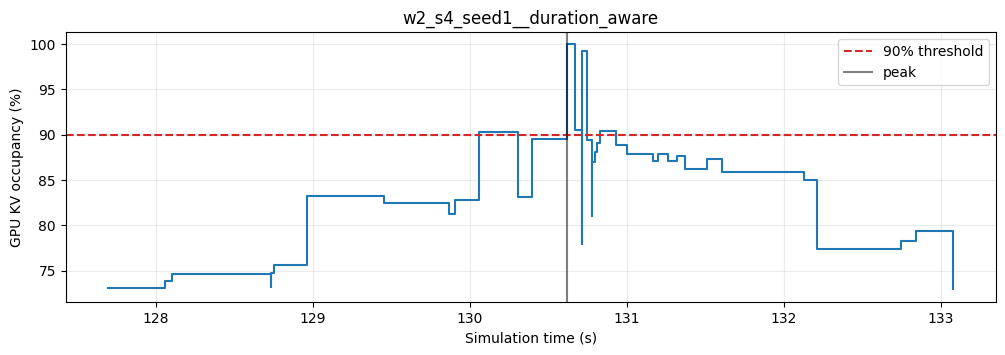

In [7]:
candidate = summary[(summary.policy == 'duration_aware') &
                    (summary.load == 'both_4x')].sort_values('peak_kv_occupancy_pct', ascending=False).iloc[0]
run_dir = OUTPUT / 'runs' / candidate.run_id
occupancy = pd.read_csv(run_dir / 'occupancy.csv')
occupancy['used_pct'] = occupancy.used_blocks / occupancy.total_blocks * 100
measured = occupancy[occupancy.time_ms >= manifest['workload_config']['warmup_ms']]
peak_row = measured.loc[measured.used_pct.idxmax()]
events = pd.read_csv(run_dir / 'events.csv')
near = events[(events.time_ms >= peak_row.time_ms - 1000) &
              (events.time_ms <= peak_row.time_ms + 1000) &
              (events.event.isin(['ADMIT', 'TOOL_START', 'OFFLOAD_START', 'OFFLOAD_DONE', 'EVICT', 'REJECT']))]
print(f'선택된 run: {candidate.run_id}, Peak: {peak_row.used_pct:.2f}% at {peak_row.time_ms:.1f} ms')
display(near[['time_ms', 'event', 'session_id', 'detail']].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(12, 3.5))
window = occupancy[(occupancy.time_ms >= peak_row.time_ms - 3000) &
                   (occupancy.time_ms <= peak_row.time_ms + 3000)]
ax.step(window.time_ms / 1000, window.used_pct, where='post')
ax.axhline(90, color='tab:red', linestyle='--', label='90% threshold')
ax.axvline(peak_row.time_ms / 1000, color='black', alpha=.5, label='peak')
ax.set(xlabel='Simulation time (s)', ylabel='GPU KV occupancy (%)', title=candidate.run_id)
ax.legend()
ax.grid(alpha=.25)
plt.show()

## 이 노트북으로 내릴 수 있는 결론의 범위

- 같은 trace 안에서 정책별 TTFT·점유율·비용 차이를 비교할 수 있다.
- `base`와 `burst`를 비교하면 도착 집중의 영향을 분리할 수 있다. `base`와 `wait`의 차이에는 대기 패턴 변화와 평균 대기 증가가 함께 포함된다.
- 기존 SLO 통과율만으로 절대 응답속도나 재계산 비용의 우열을 판단하지 않는다.
- 현재 Duration-Aware의 예상 대기는 실제 미래 대기를 사용한다. 현실형 예측 정책의 결과가 아니다.
- 모델의 prefill·decode·PCIe 값은 실측 전이다. 실제 GPU 성능을 주장하려면 보정과 민감도 분석이 추가로 필요하다.

**이 설정에서 확인한 점:** W0도 정책에 따라 3~4/5만 통과합니다. 따라서 W2가 악화시킨 부분과 장기 실행 자체가 드러낸 용량 경계를 구분해 읽어야 합니다.

## 7. 전체 실행 결과: 모든 정책 · 워크로드 · seed

아래 **두 표**는 9개 워크로드 조건 × 5개 정책 × 5개 seed = 225개 실행을 정책 → 워크로드 → seed 순으로 보여준다. 첫 표는 SLO 판정에 쓰이는 지표만, 둘째 표는 원인 분석용 부수 지표를 담았다. 코드 셀 맨 위의 `LOADS_TO_SHOW`, `POLICIES_TO_SHOW`, `SEEDS_TO_SHOW`를 바꾸면 두 표가 함께 필터링된다. 기본값 `None`은 전체 표시다.

`TTFT 배율`은 같은 정책·seed의 W0 1× 대비 값이다. 최종 SLO는 TTFT 배율 ≤ 3, 일반 요청 거부율 ≤ 10%, Peak KV ≤ 90%를 모두 만족해야 통과한다. `90% 초과 시간`은 10~180초 구간이고, Peak는 워밍업 10초 이후 실행 종료까지의 최고값이다.

In [8]:
from IPython.display import HTML

# None이면 전체 표시. 예: ['both_2x', 'both_4x'], ['duration_aware'], [0, 3, 4]
LOADS_TO_SHOW = None
POLICIES_TO_SHOW = None
SEEDS_TO_SHOW = None

expected = pd.MultiIndex.from_product(
    [manifest['policies'], [item['load'] for item in manifest['conditions']], manifest['seeds']],
    names=['policy', 'load', 'seed'],
).to_frame(index=False)
all_results = expected.merge(summary, on=['load', 'policy', 'seed'], how='left', validate='one_to_one')
all_results = all_results.merge(
    slo[['load', 'policy', 'seed', 'w0_p95_ttft_ms', 'ttft_ratio_vs_policy_w0',
         'ttft_pass', 'reject_pass', 'occupancy_pass', 'all_pass']],
    on=['load', 'policy', 'seed'], how='left', validate='one_to_one',
)
assert len(all_results) == 225 and all_results.run_id.notna().all() and all_results.all_pass.notna().all()

shown = all_results
for column, allowed in [('load', LOADS_TO_SHOW), ('policy', POLICIES_TO_SHOW), ('seed', SEEDS_TO_SHOW)]:
    if allowed is not None:
        shown = shown[shown[column].isin(allowed)]

slo_table = pd.DataFrame({
    '정책': shown.policy, '워크로드': shown.load, 'seed': shown.seed,
    'W0 P95 TTFT (ms)': shown.w0_p95_ttft_ms.round(2),
    'P95 TTFT (ms)': shown.normal_p95_ttft_ms.round(2),
    'TTFT 배율': shown.ttft_ratio_vs_policy_w0.round(2),
    'TTFT 판정': shown.ttft_pass.map({True: '통과', False: '실패'}),
    '일반 요청 거부율 (%)': shown.normal_reject_rate_pct.round(2),
    '거부율 판정': shown.reject_pass.map({True: '통과', False: '실패'}),
    'Peak KV (%)': shown.peak_kv_occupancy_pct.round(2),
    'Peak 판정': shown.occupancy_pass.map({True: '통과', False: '실패'}),
    '최종 SLO': shown.all_pass.map({True: '통과', False: '실패'}),
})
secondary_table = pd.DataFrame({
    '정책': shown.policy, '워크로드': shown.load, 'seed': shown.seed,
    '90% 초과 시간 (초)': (shown.kv_above_90_ms / 1000).round(3),
    '90% 초과 비율 (%)': shown.kv_above_90_pct_of_time.round(2),
    '평균 KV (%)': shown.mean_kv_occupancy_pct.round(2),
    'Stress P95 완료 (초)': (shown.stress_p95_completion_ms / 1000).round(2),
    '작업 완료 평균 (초)': (shown.task_completion_mean_ms / 1000).round(2),
    '작업 완료 P95 (초)': (shown.task_completion_p95_ms / 1000).round(2),
    '일반 P50 TTFT (ms)': shown.normal_p50_ttft_ms.round(2),
    '전체 P95 TTFT (ms)': shown.all_p95_ttft_ms.round(2),
    '처리량 (작업/초)': shown.throughput_jobs_per_s.round(4),
    '일반 제출 수': shown.normal_submitted,
    '일반 완료 수': shown.normal_completed,
    '일반 거부 수': shown.normal_rejected,
    '완료 작업 수': shown.completed_jobs,
    '거부 작업 수': shown.rejected_jobs,
    'Stress 제출 수': shown.stress_submitted_jobs,
    'Stress 완료 수': shown.stress_completed_jobs,
    'Evict 횟수': shown.eviction_count,
    'Evict/완료작업': shown.eviction_per_job.round(3),
    'Offload 횟수': shown.offload_count,
    'Reload 횟수': shown.reload_count,
    '전송량 (GiB)': (shown.transfer_bytes / 2**30).round(3),
    '전송량/완료작업 (GiB)': shown.transfer_gib_per_job.round(3),
    '재계산 토큰': shown.recomputed_tokens,
    '재계산 토큰/완료작업': shown.recomputed_tokens_per_job.round(2),
    'Prefill 사용률 (%)': shown.prefill_busy_pct.round(2),
    'PCIe 사용률 (%)': shown.pcie_busy_pct.round(2),
    '전체 세션 수': shown.sessions,
    '실행 종료 (초)': (shown.end_ms / 1000).round(2),
})
for title, frame in [('SLO 판정', slo_table), ('부수 지표', secondary_table)]:
    display(HTML(
        f'<h3>{title}</h3><p>표시: {len(frame)} / {len(all_results)}개 실행</p>'
        '<div style="max-height:650px; max-width:100%; overflow:auto; border:1px solid #ddd">'
        + frame.to_html(index=False, escape=True) + '</div>'
    ))

정책,워크로드,seed,W0 P95 TTFT (ms),P95 TTFT (ms),TTFT 배율,TTFT 판정,일반 요청 거부율 (%),거부율 판정,Peak KV (%),Peak 판정,최종 SLO
pin_all,w0_1x,0,108.37,108.37,1.00,통과,0.00,통과,63.12,통과,통과
pin_all,w0_1x,1,314.54,314.54,1.00,통과,0.00,통과,100.00,실패,실패
pin_all,w0_1x,2,231.84,231.84,1.00,통과,0.00,통과,84.36,통과,통과
pin_all,w0_1x,3,2275.42,2275.42,1.00,통과,0.00,통과,100.00,실패,실패
pin_all,w0_1x,4,287.09,287.09,1.00,통과,0.00,통과,80.60,통과,통과
pin_all,base_2x,0,108.37,108.37,1.00,통과,0.00,통과,94.32,실패,실패
pin_all,base_2x,1,314.54,26621.83,84.64,실패,0.00,통과,100.00,실패,실패
pin_all,base_2x,2,231.84,1660.58,7.16,실패,0.00,통과,99.91,실패,실패
pin_all,base_2x,3,2275.42,29479.92,12.96,실패,6.77,통과,100.00,실패,실패
pin_all,base_2x,4,287.09,315.74,1.10,통과,0.00,통과,99.32,실패,실패


정책,워크로드,seed,90% 초과 시간 (초),90% 초과 비율 (%),평균 KV (%),Stress P95 완료 (초),작업 완료 평균 (초),작업 완료 P95 (초),일반 P50 TTFT (ms),전체 P95 TTFT (ms),처리량 (작업/초),일반 제출 수,일반 완료 수,일반 거부 수,완료 작업 수,거부 작업 수,Stress 제출 수,Stress 완료 수,Evict 횟수,Evict/완료작업,Offload 횟수,Reload 횟수,전송량 (GiB),전송량/완료작업 (GiB),재계산 토큰,재계산 토큰/완료작업,Prefill 사용률 (%),PCIe 사용률 (%),전체 세션 수,실행 종료 (초)
pin_all,w0_1x,0,0.000,0.00,37.52,31.17,3.95,16.59,43.50,398.88,1.7069,357,357,0,381,0,24,24,0,0.000,0,0,0.000,0.000,0,0.00,11.95,0.00,399,233.21
pin_all,w0_1x,1,8.140,4.79,38.01,29.50,4.16,17.54,44.25,473.50,1.7140,334,334,0,362,0,28,28,0,0.000,0,0,0.000,0.000,0,0.00,12.43,0.00,378,221.20
pin_all,w0_1x,2,0.000,0.00,46.31,29.37,4.28,16.91,42.75,428.75,1.9052,358,358,0,392,0,34,34,0,0.000,0,0,0.000,0.000,0,0.00,14.11,0.00,406,215.75
pin_all,w0_1x,3,25.439,14.96,53.21,30.98,5.04,22.50,46.20,2275.42,1.8012,325,325,0,365,0,40,40,0,0.000,0,0,0.000,0.000,0,0.00,15.24,0.00,392,212.64
pin_all,w0_1x,4,0.000,0.00,44.08,28.22,4.46,20.60,45.50,411.01,1.6581,318,318,0,355,0,37,37,0,0.000,0,0,0.000,0.000,0,0.00,13.30,0.00,375,224.10
pin_all,base_2x,0,1.473,0.87,50.73,44.72,4.58,23.26,43.75,407.75,1.6035,357,357,0,381,0,24,24,0,0.000,0,0,0.000,0.000,0,0.00,11.26,0.00,399,247.60
pin_all,base_2x,1,35.382,20.81,53.94,76.83,11.07,31.03,54.03,26621.83,1.4574,334,334,0,360,2,28,26,0,0.000,0,0,0.000,0.000,0,0.00,10.49,0.00,378,257.02
pin_all,base_2x,2,23.996,14.11,63.01,45.81,5.25,24.45,45.75,1660.58,1.7996,358,358,0,392,0,34,34,0,0.000,0,0,0.000,0.000,0,0.00,13.36,0.00,406,227.82
pin_all,base_2x,3,96.041,56.49,78.31,119.21,19.26,33.94,12914.87,29692.73,1.3573,325,303,22,329,36,40,26,0,0.000,0,0,0.000,0.000,0,0.00,10.33,0.00,392,252.39
pin_all,base_2x,4,13.121,7.72,60.00,41.75,5.36,29.47,45.38,422.20,1.5827,318,318,0,355,0,37,37,0,0.000,0,0,0.000,0.000,0,0.00,12.72,0.00,375,234.30


## 8. 정책·seed별 워크로드 변화 그래프

**읽는 법:** 각 그래프의 5개 패널은 정책, 색 선은 seed 0~4, 검은 선은 다섯 seed의 평균이다. 가로축은 W0 1×, 2×의 base·burst·wait·both, 4×의 base·burst·wait·both 순서다. W0·2×·4× 사이의 선은 끊어서 서로 다른 조건 묶음임을 표시했다. **패널마다 세로축 범위가 달라** 정책 간 절댓값은 표에서 확인한다.

먼저 통과/실패 히트맵을 보고, 이어서 SLO·지연·메모리·정책 비용·자원 사용·작업 수의 **모든 수치 지표**를 한 지표당 한 그래프로 볼 수 있다. 작업 완료시간에는 설정한 도구 대기시간 자체가 포함된다. 90% 초과 시간과 평균 KV는 10~180초 구간, Peak는 워밍업 이후 실행 종료까지다.

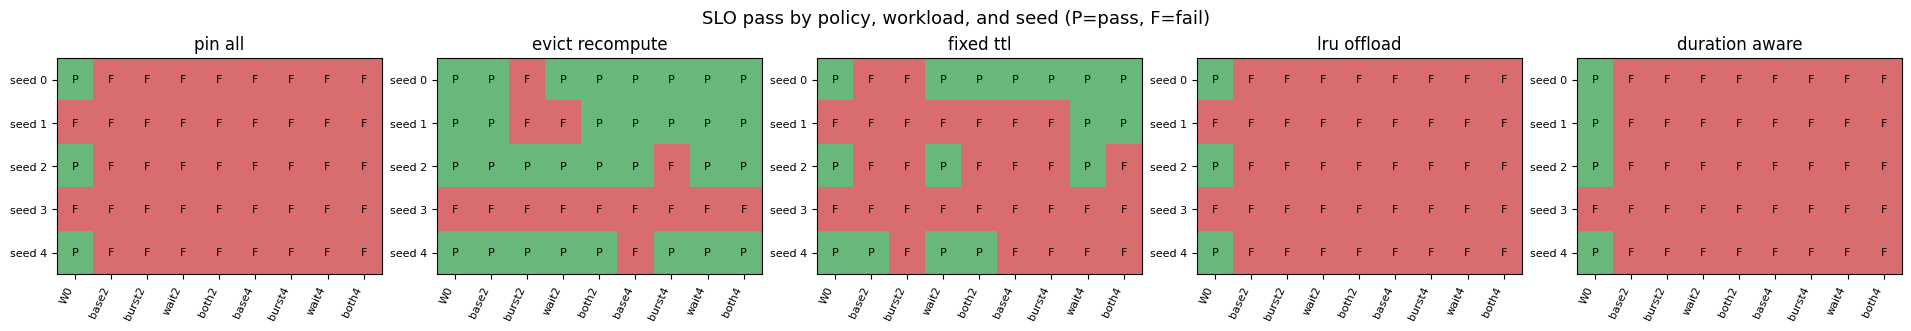

SLO 지표와 W0 대비 배율

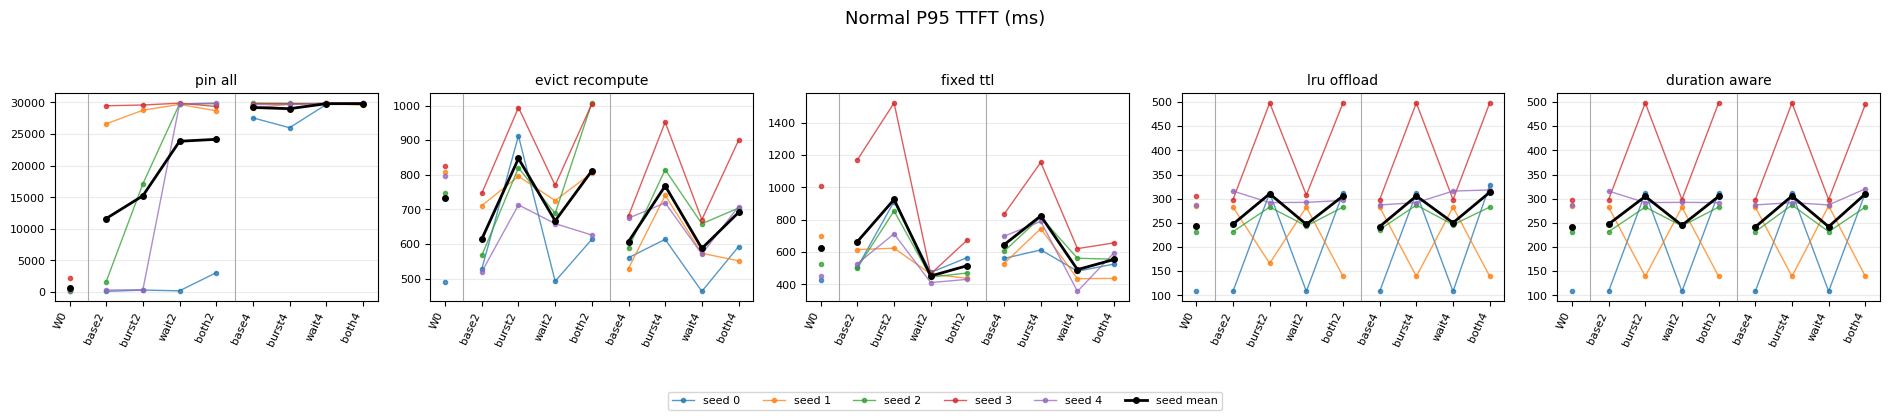

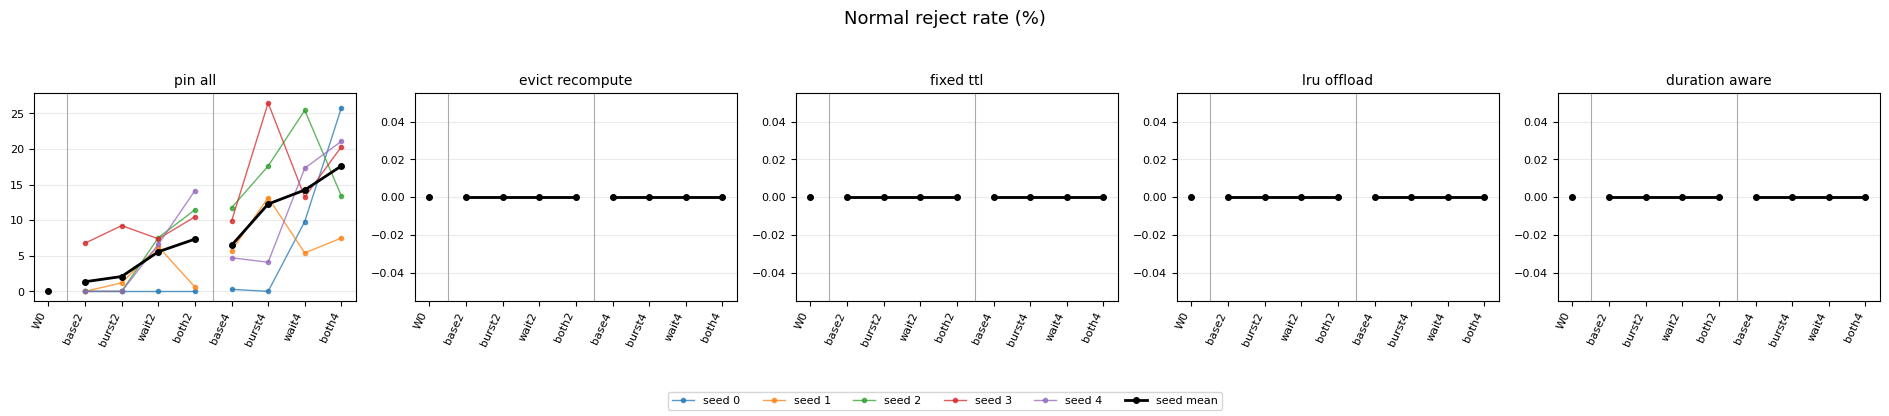

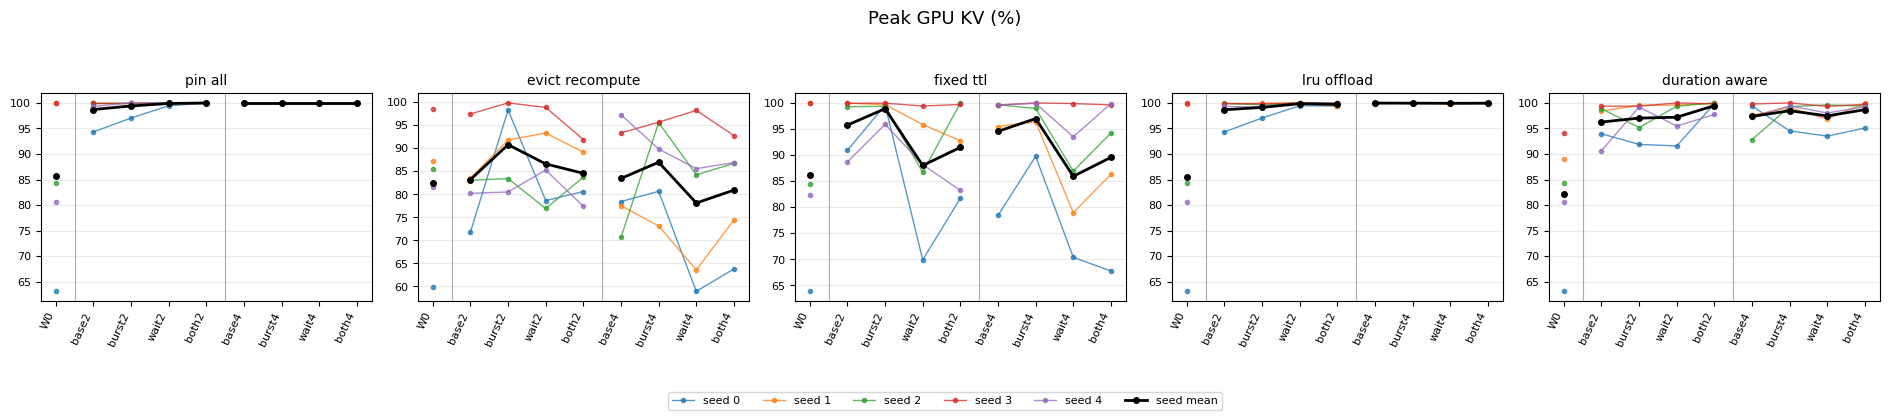

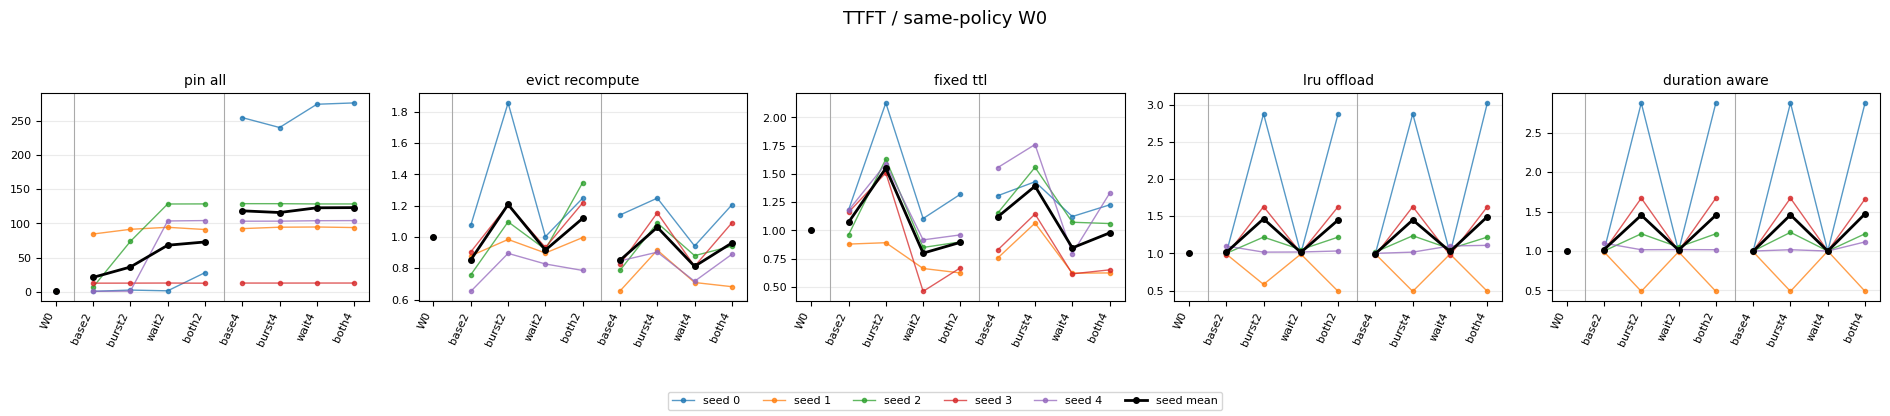

응답 지연과 작업 완료

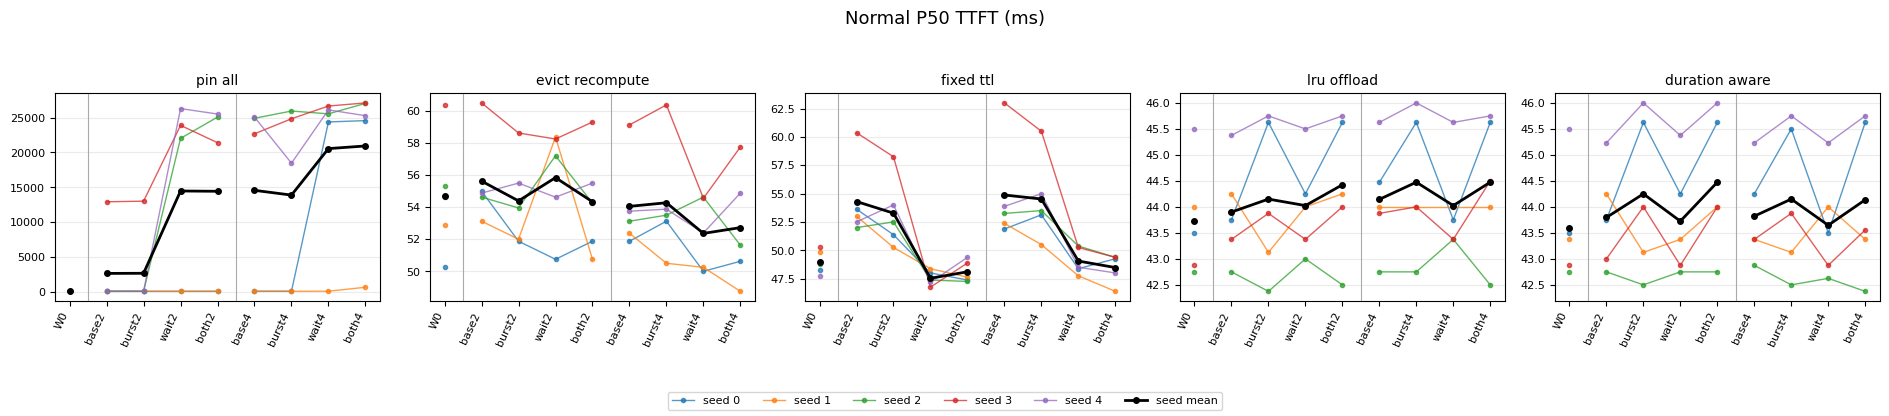

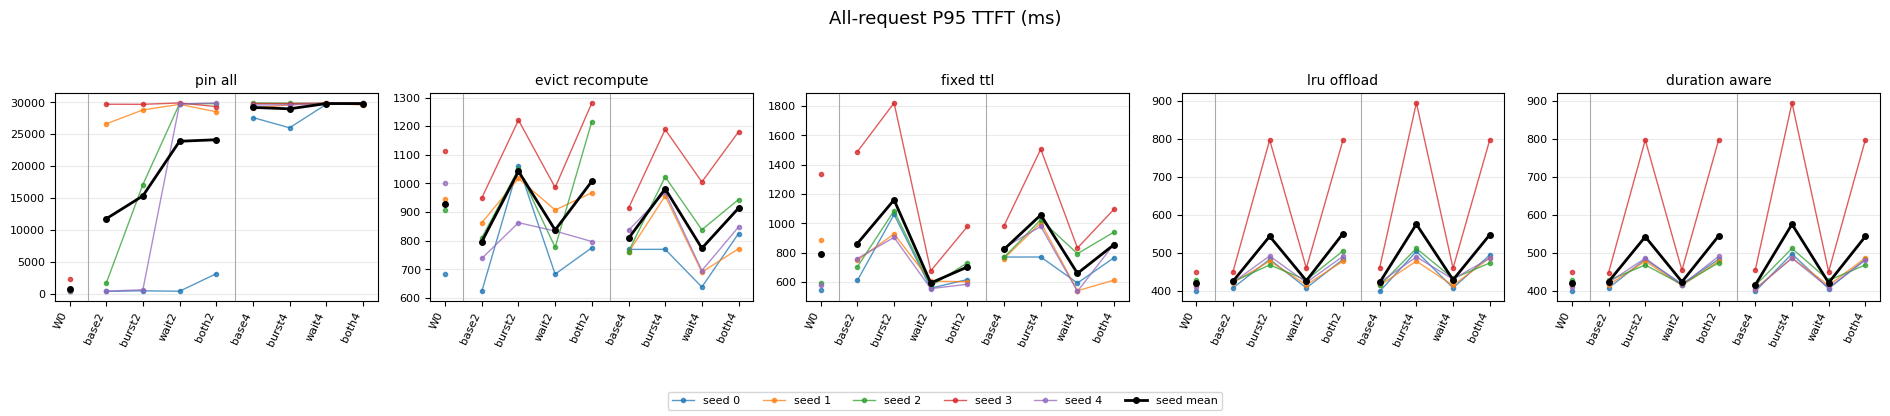

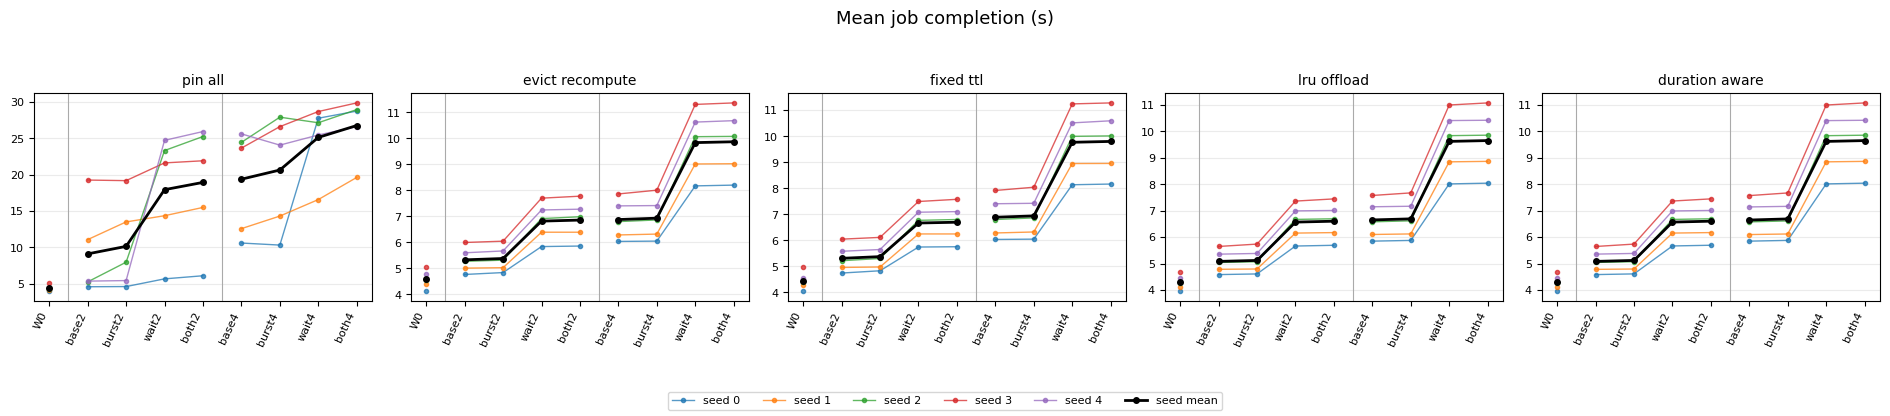

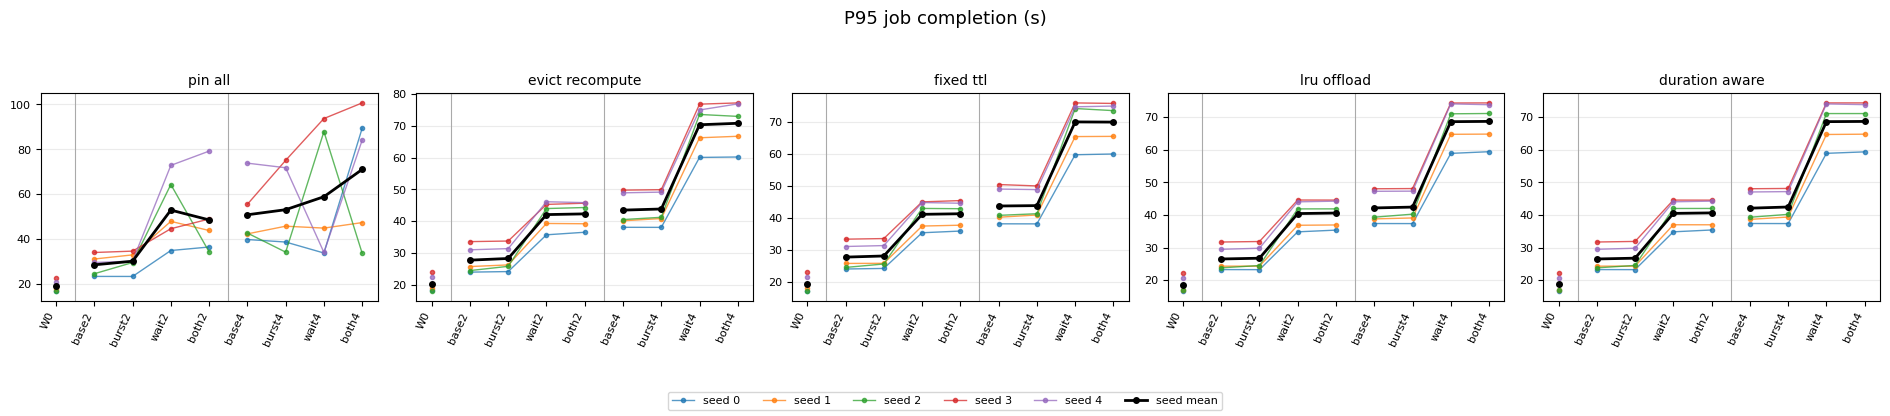

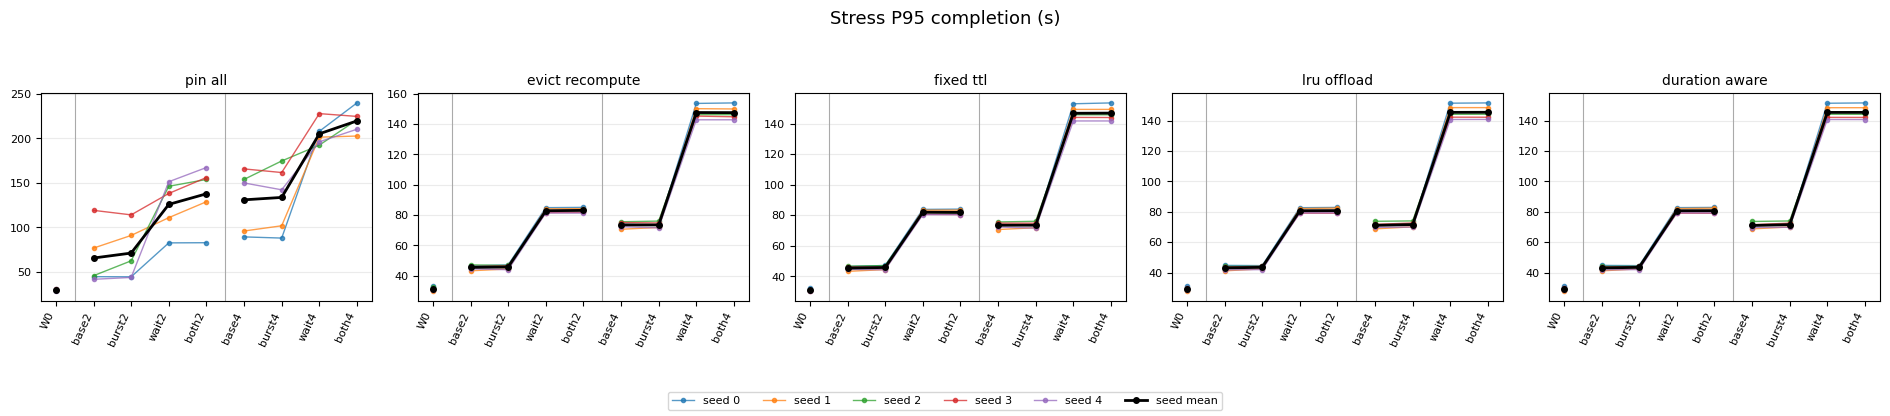

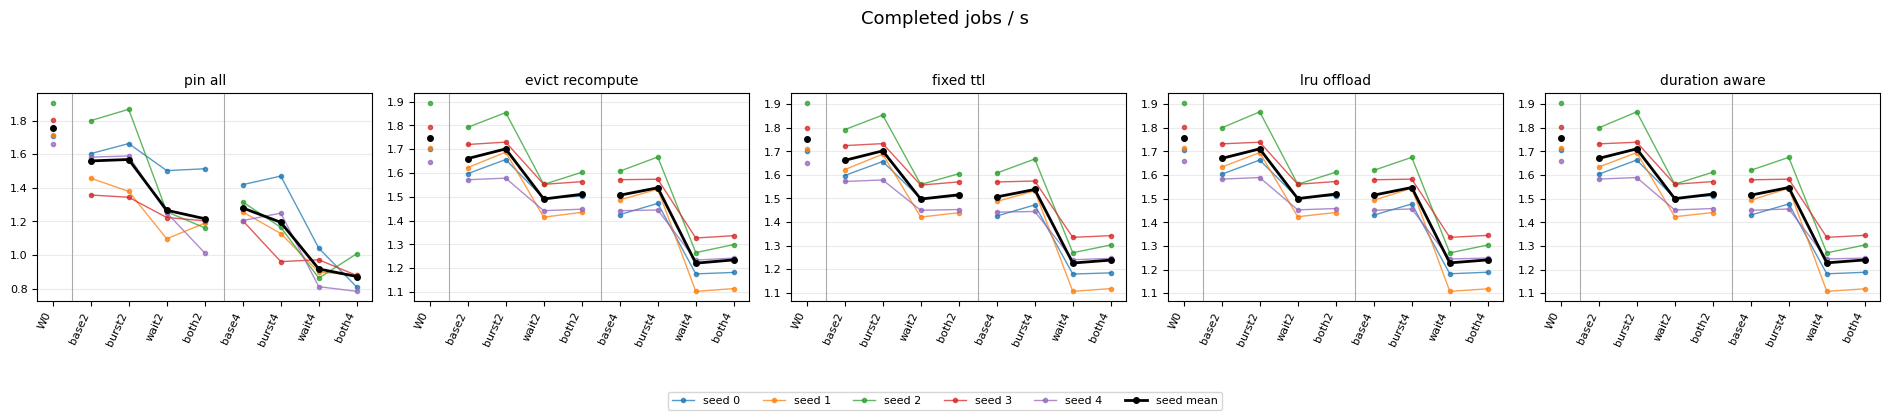

GPU KV 점유

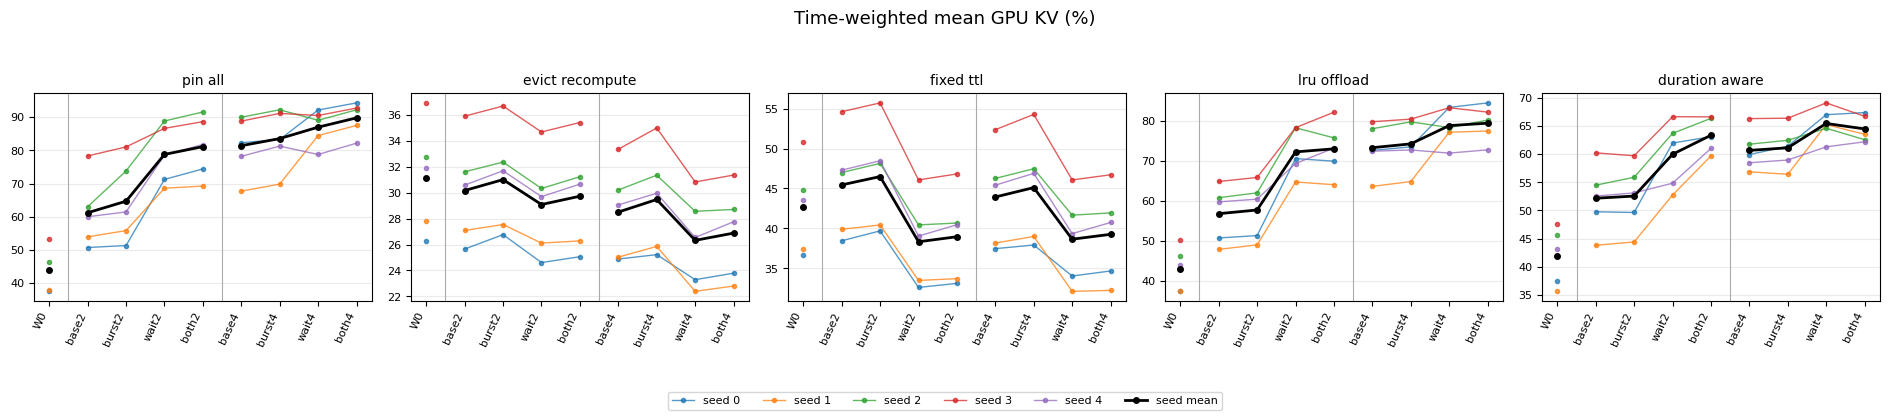

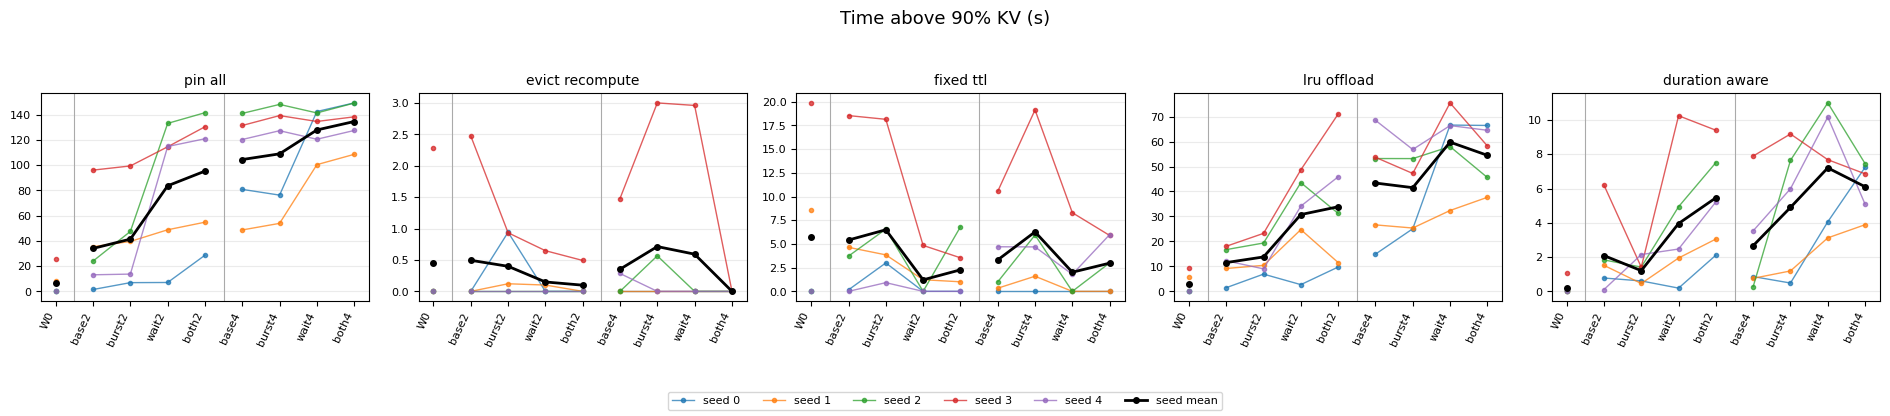

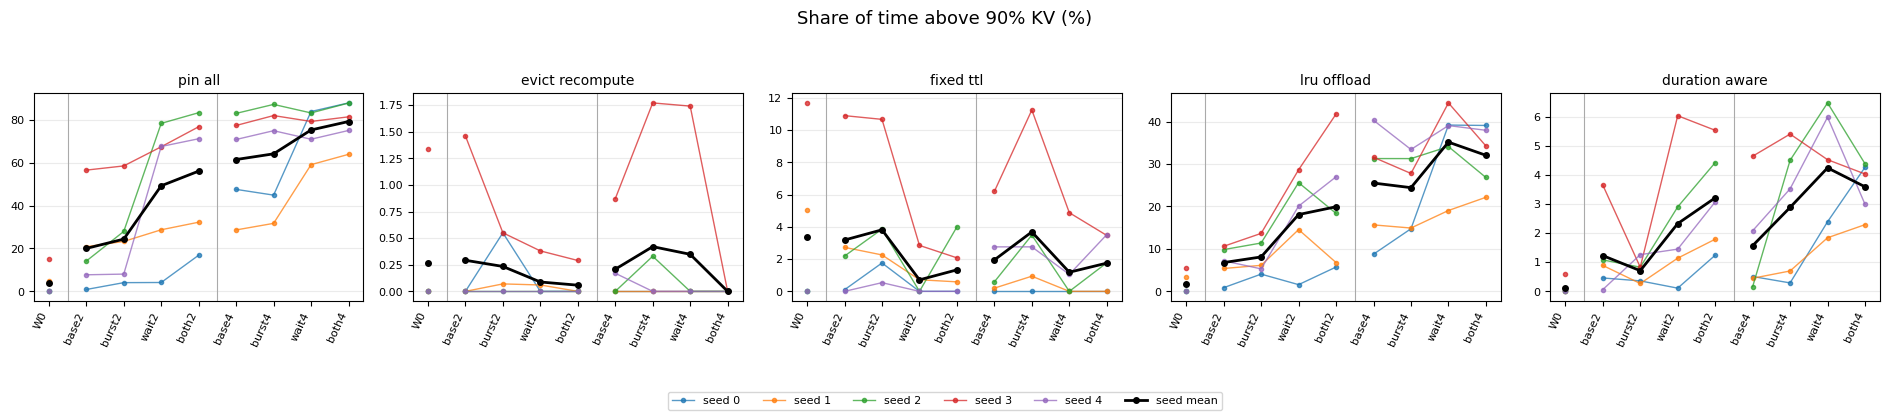

KV 관리 비용

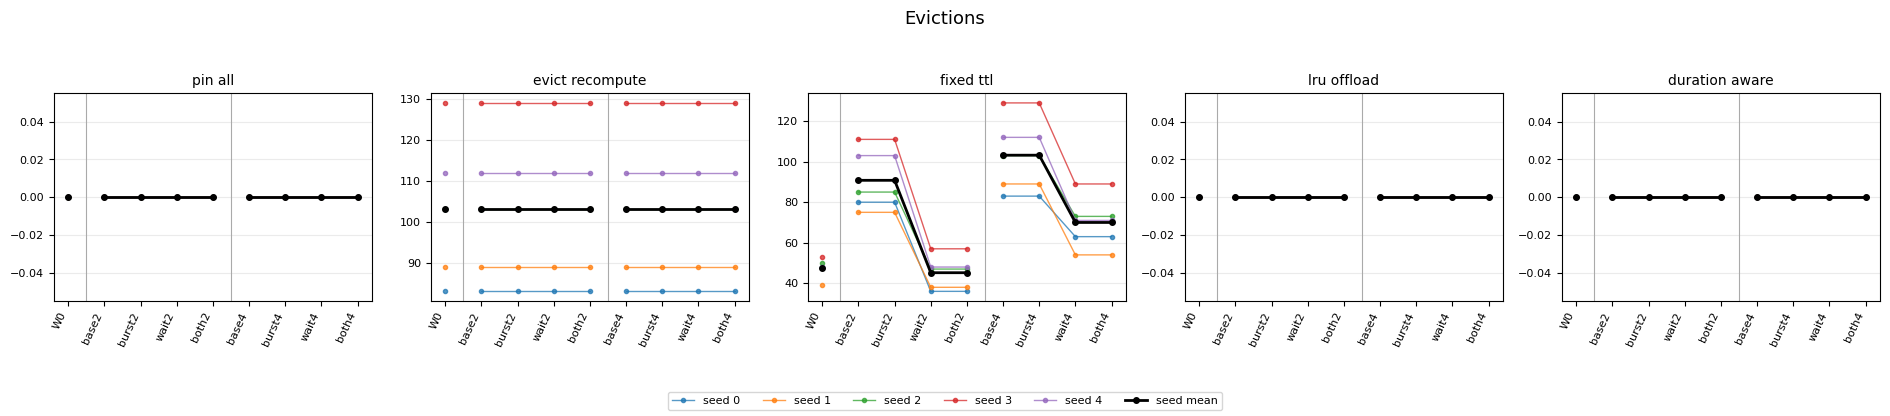

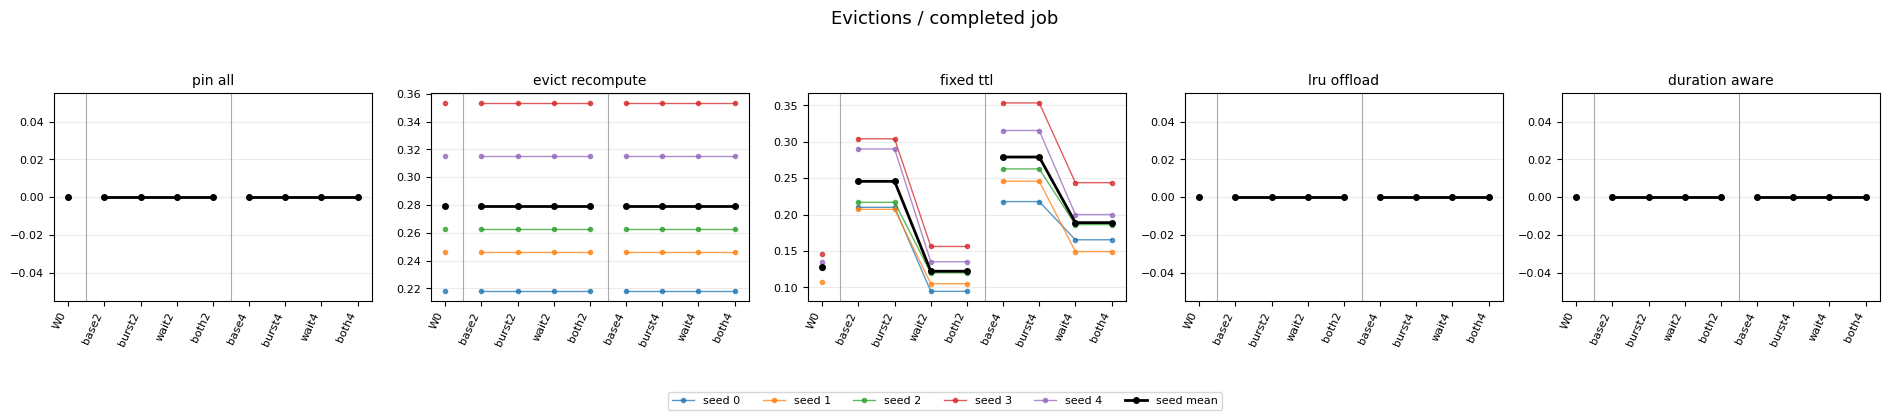

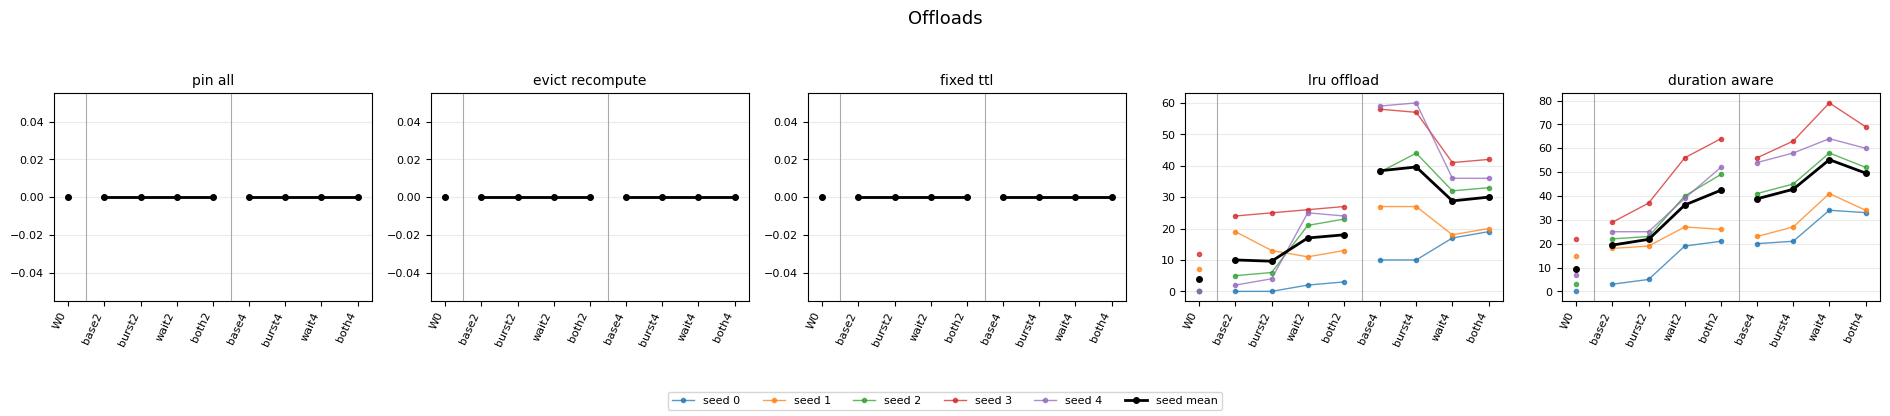

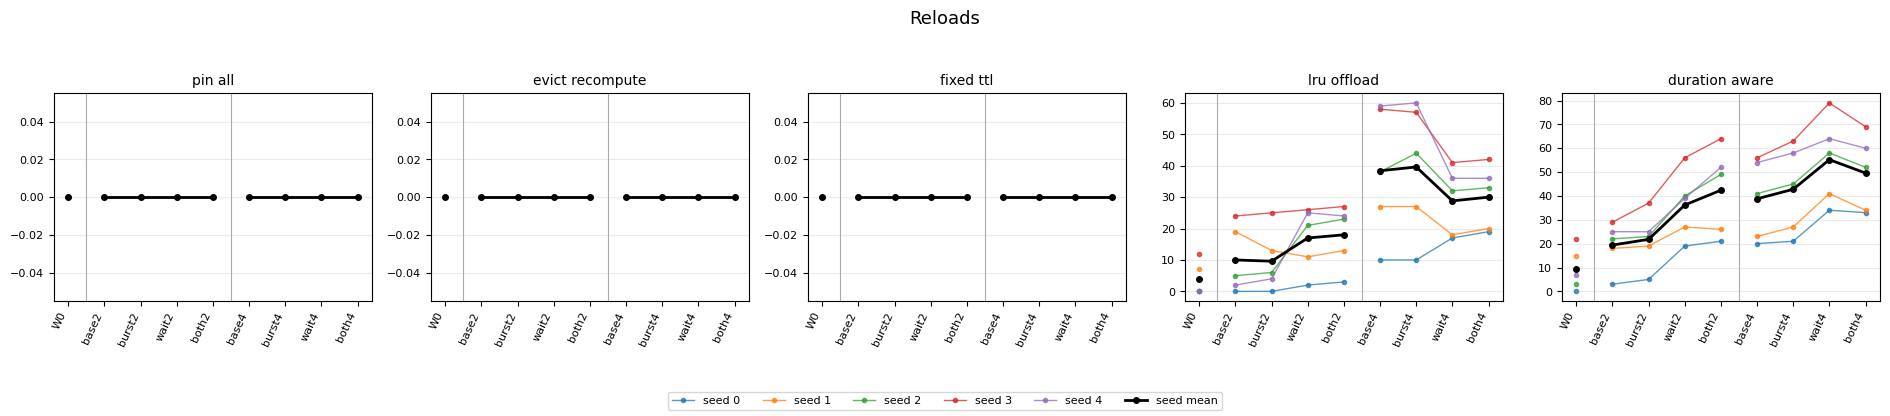

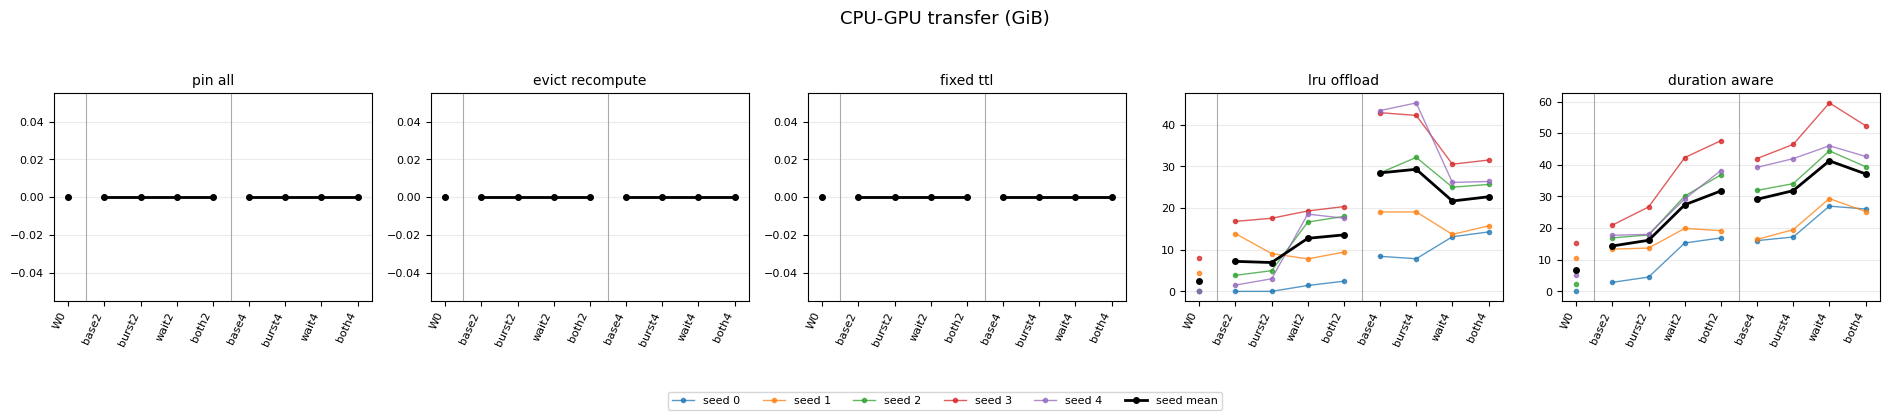

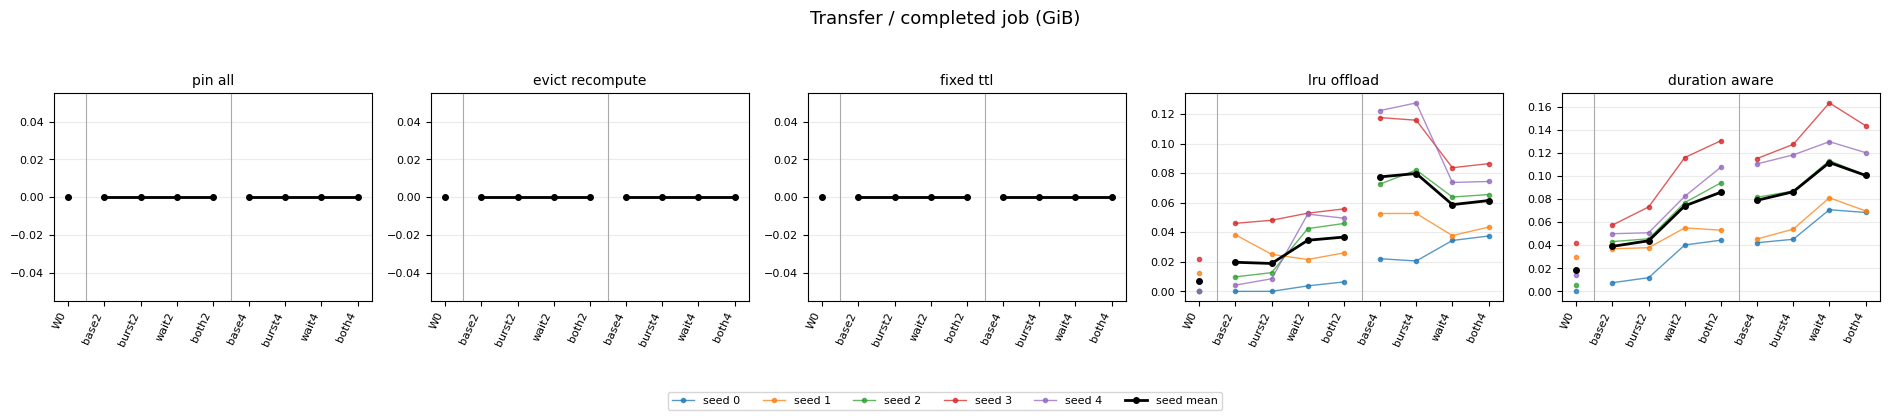

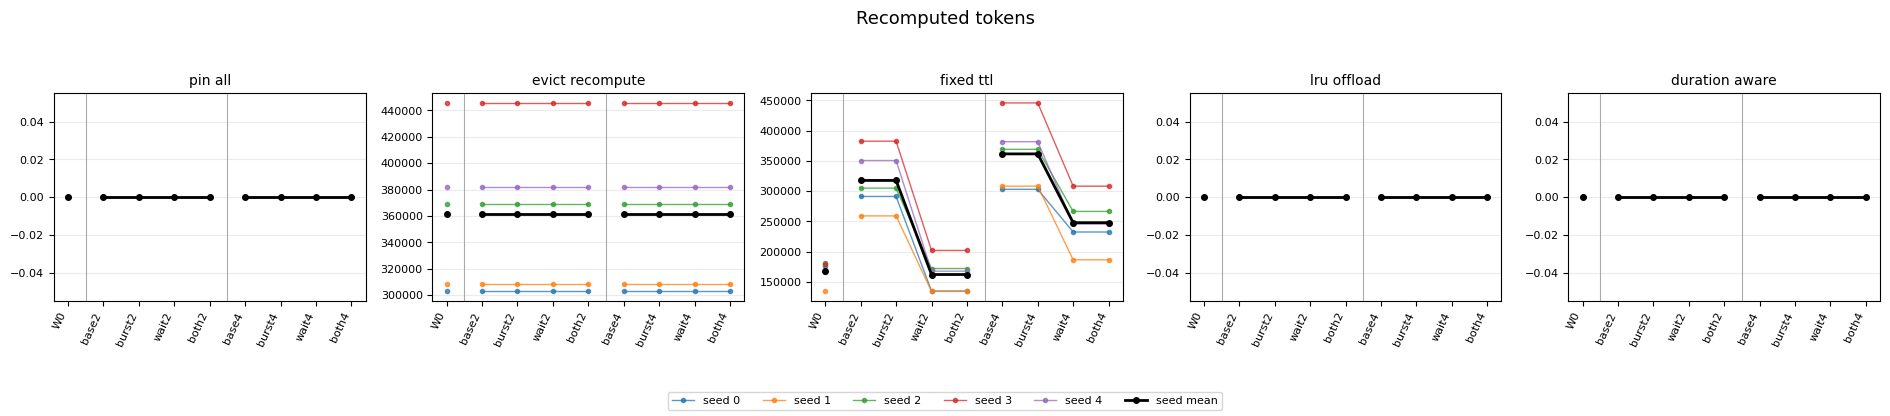

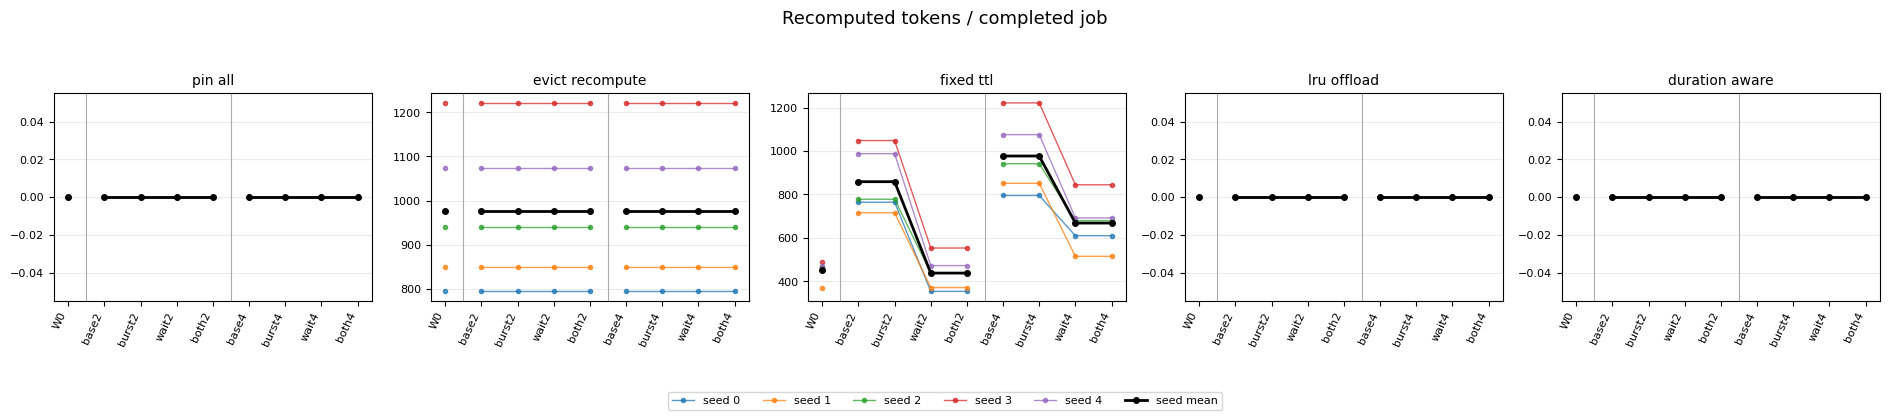

자원 사용률

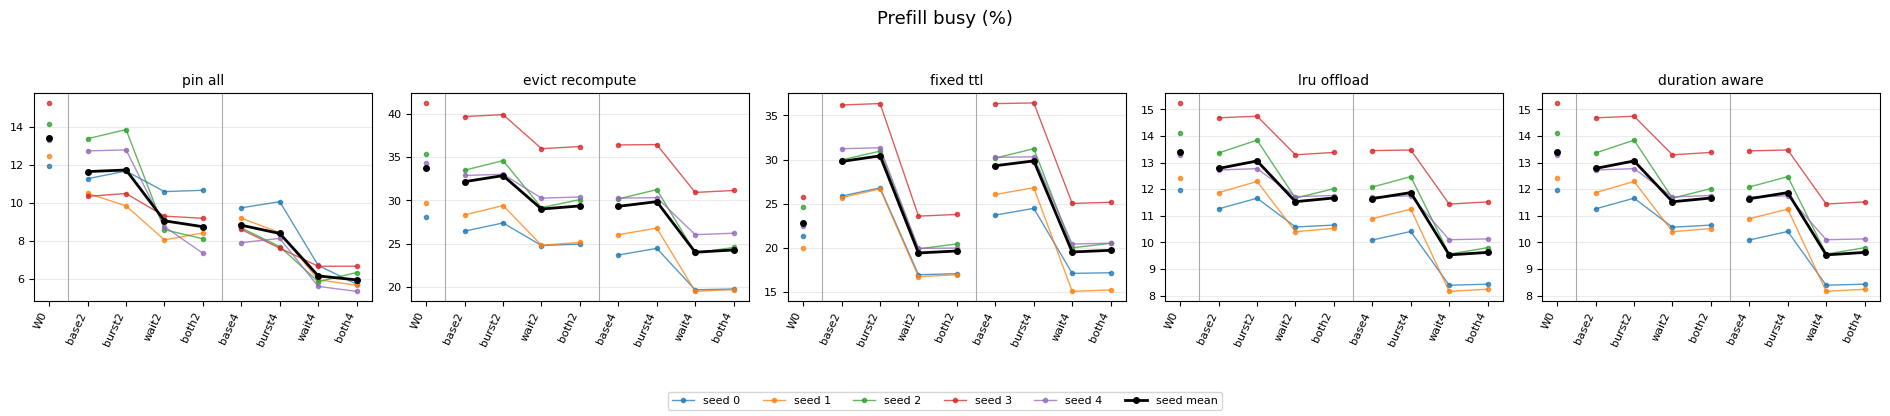

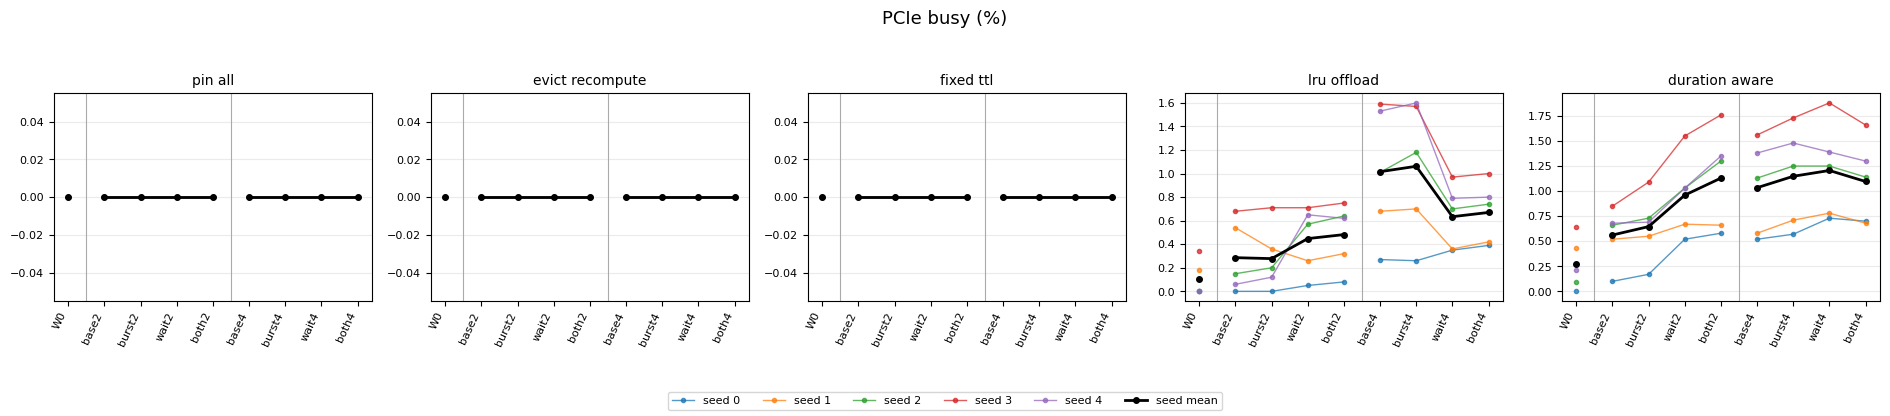

요청 수와 실행 길이

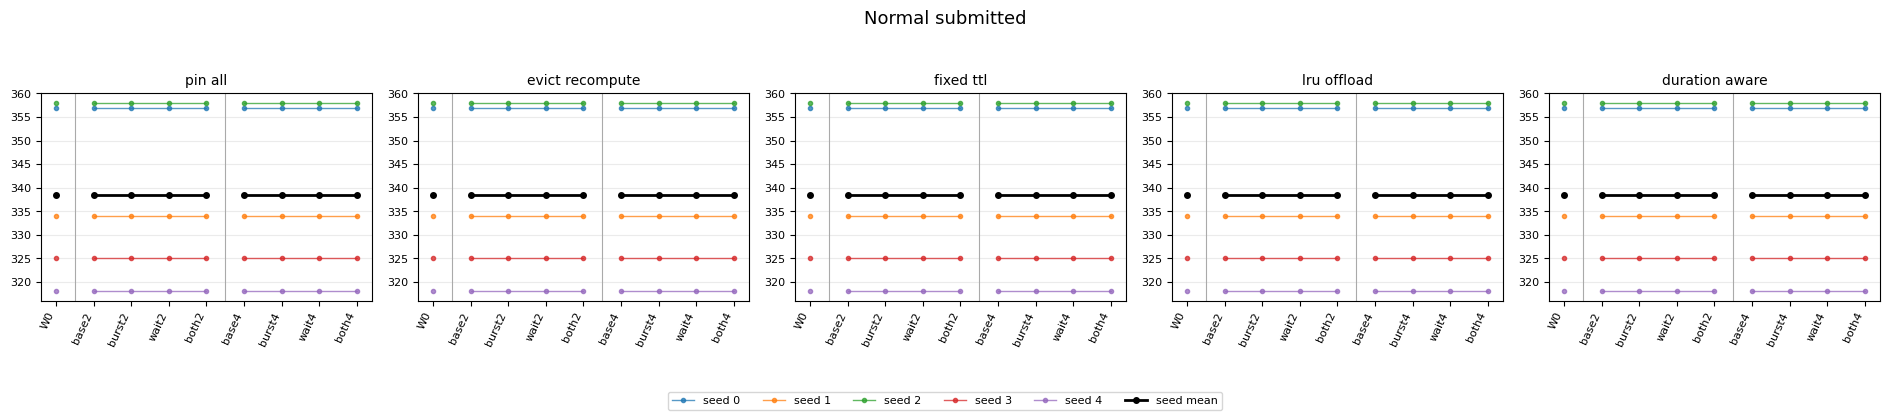

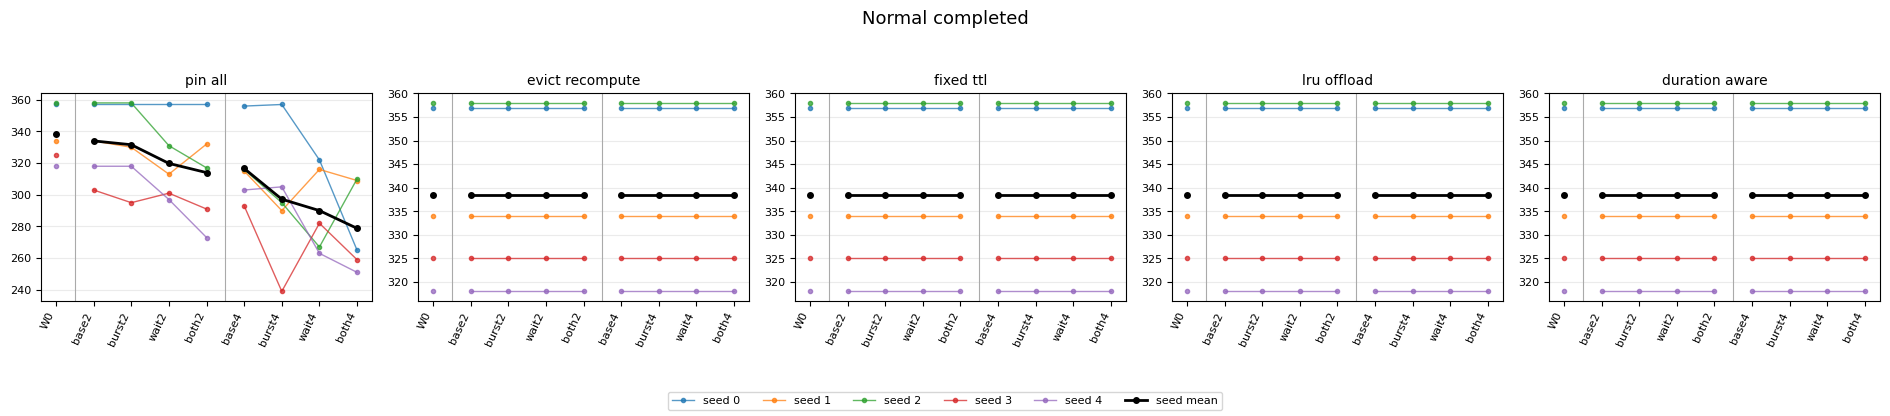

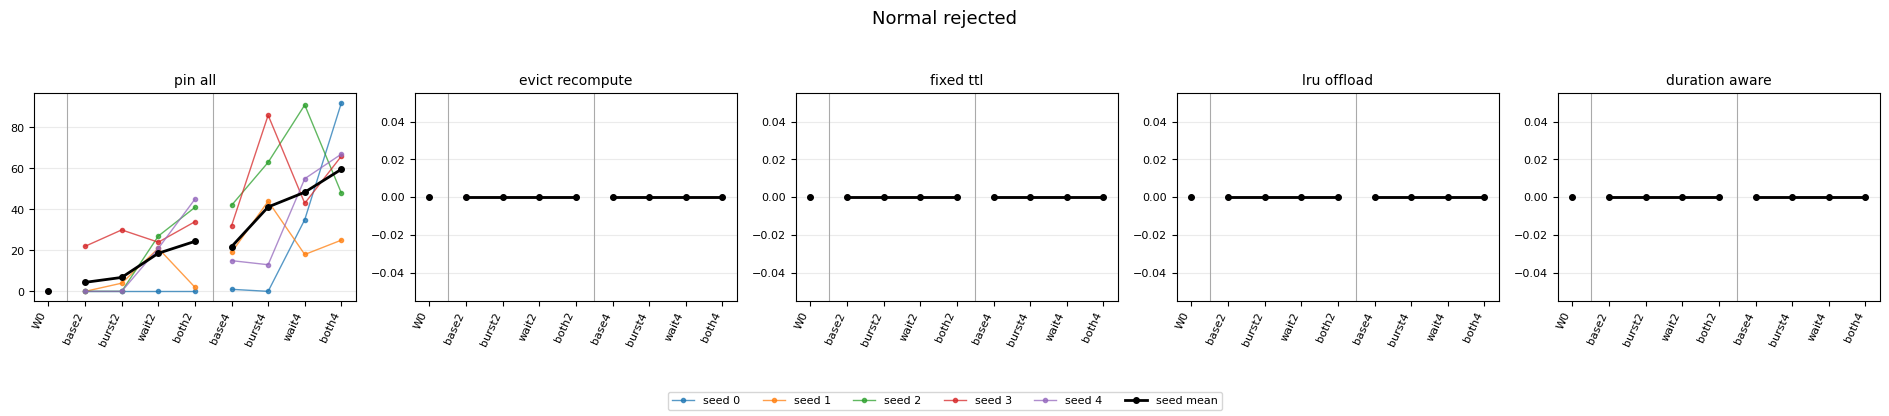

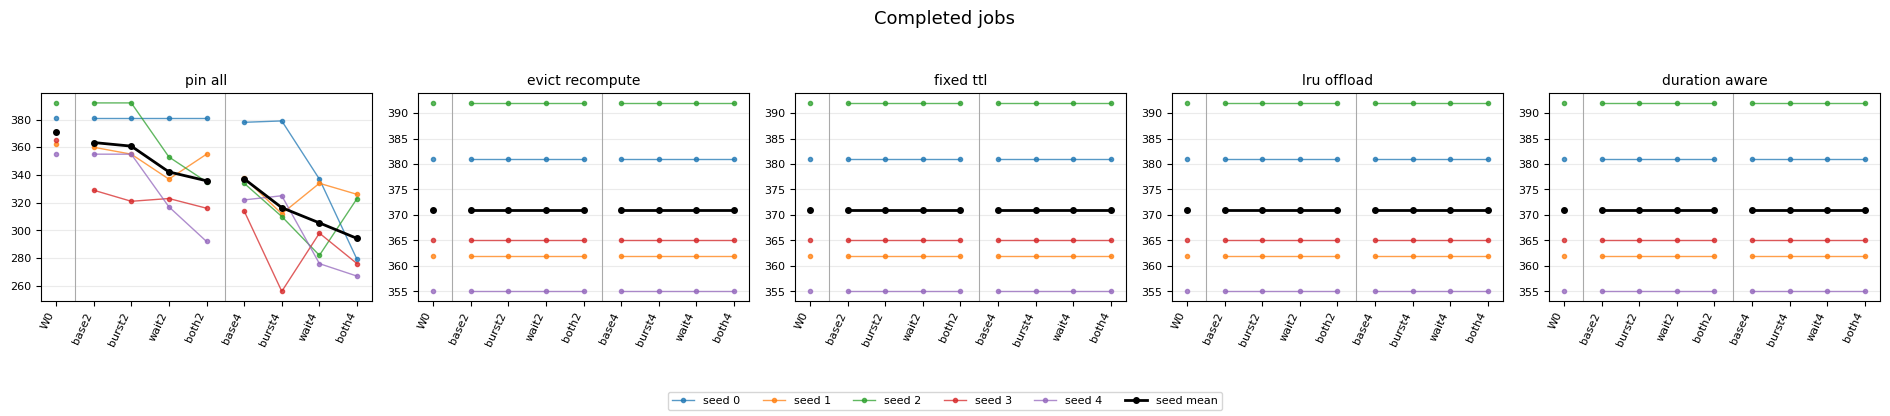

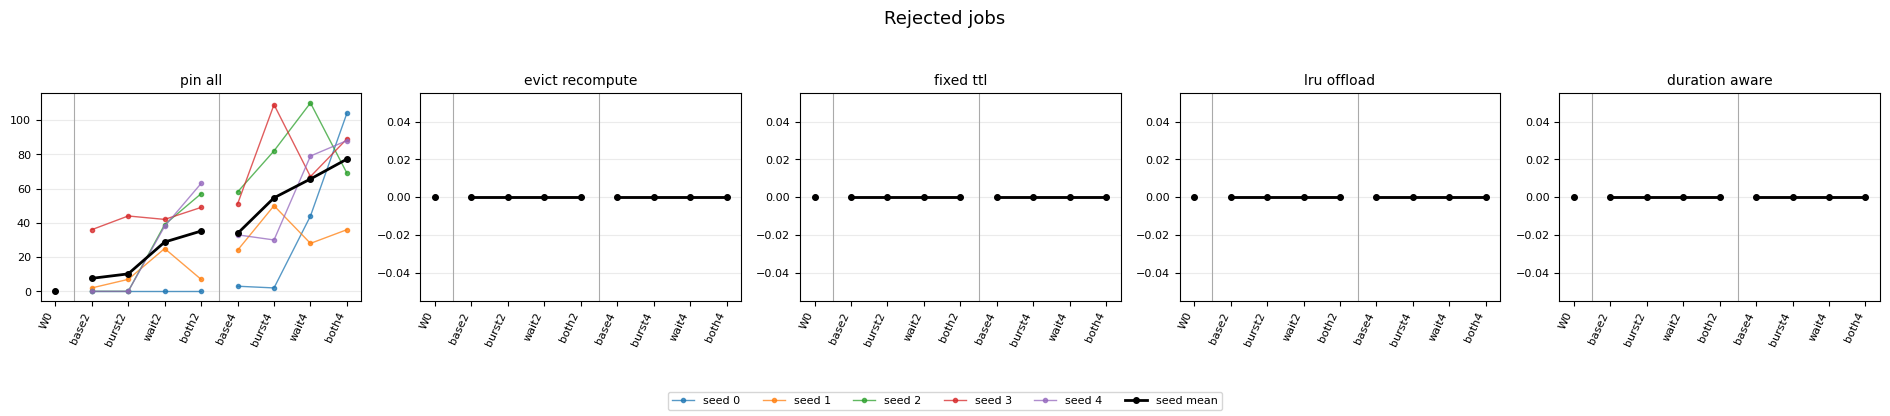

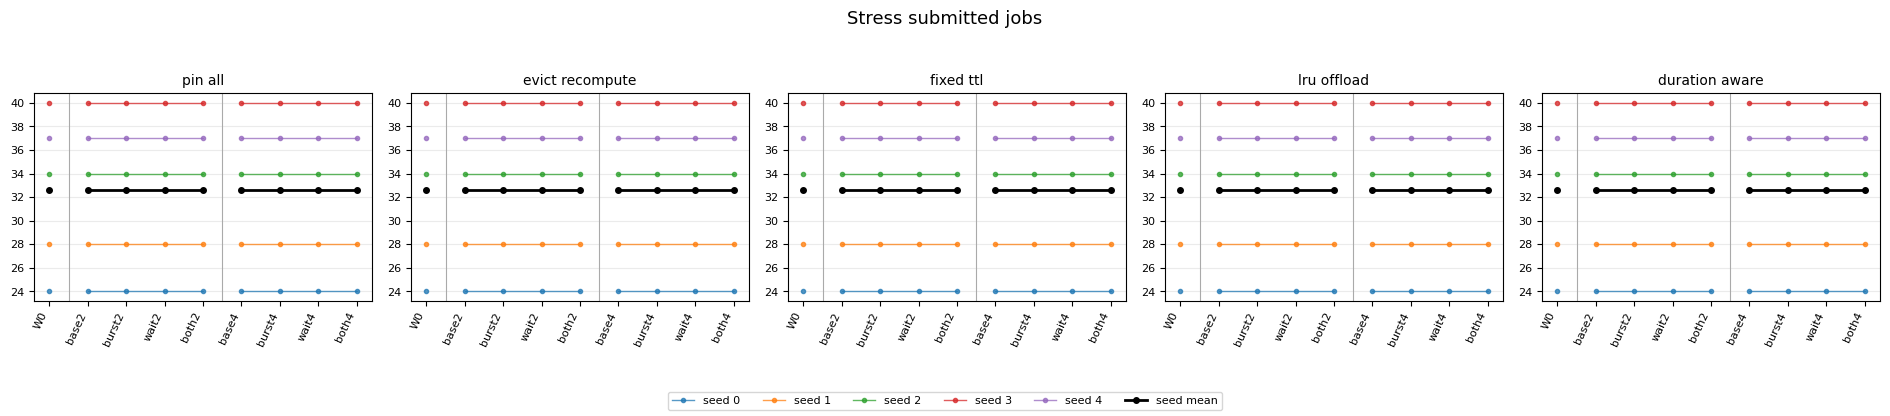

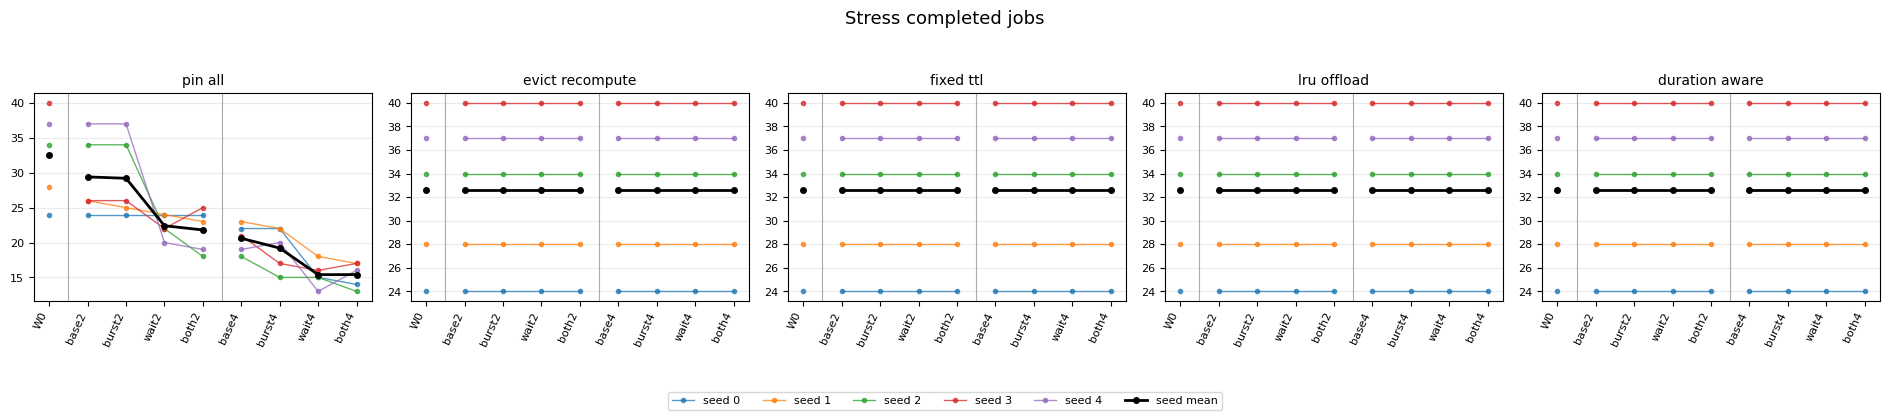

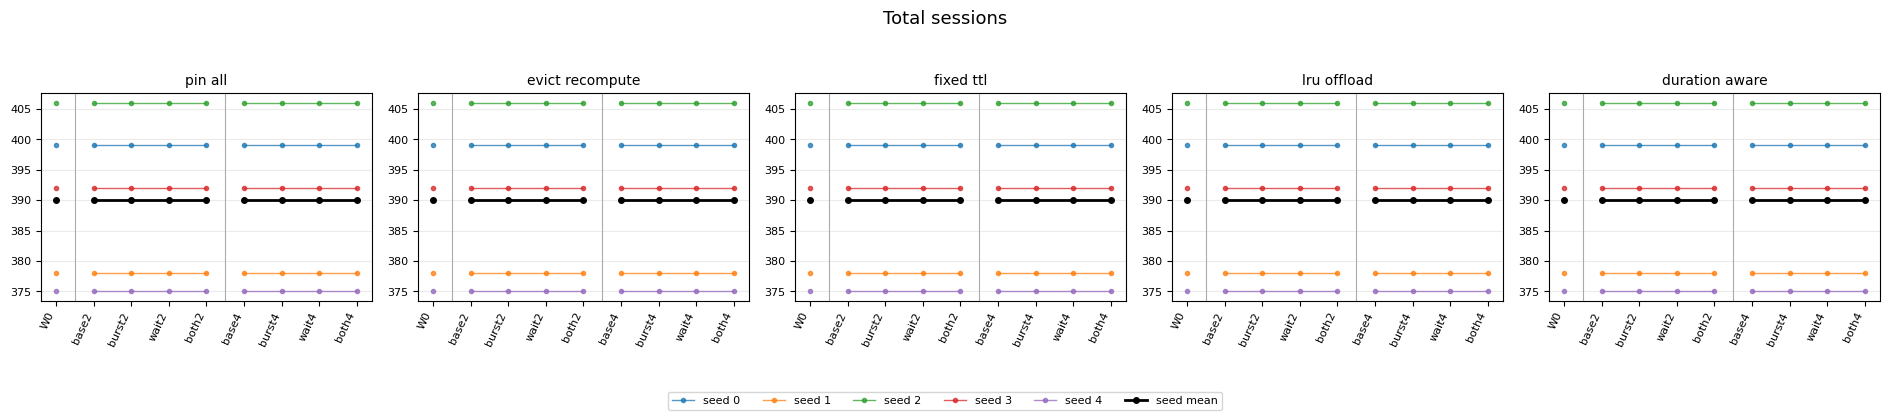

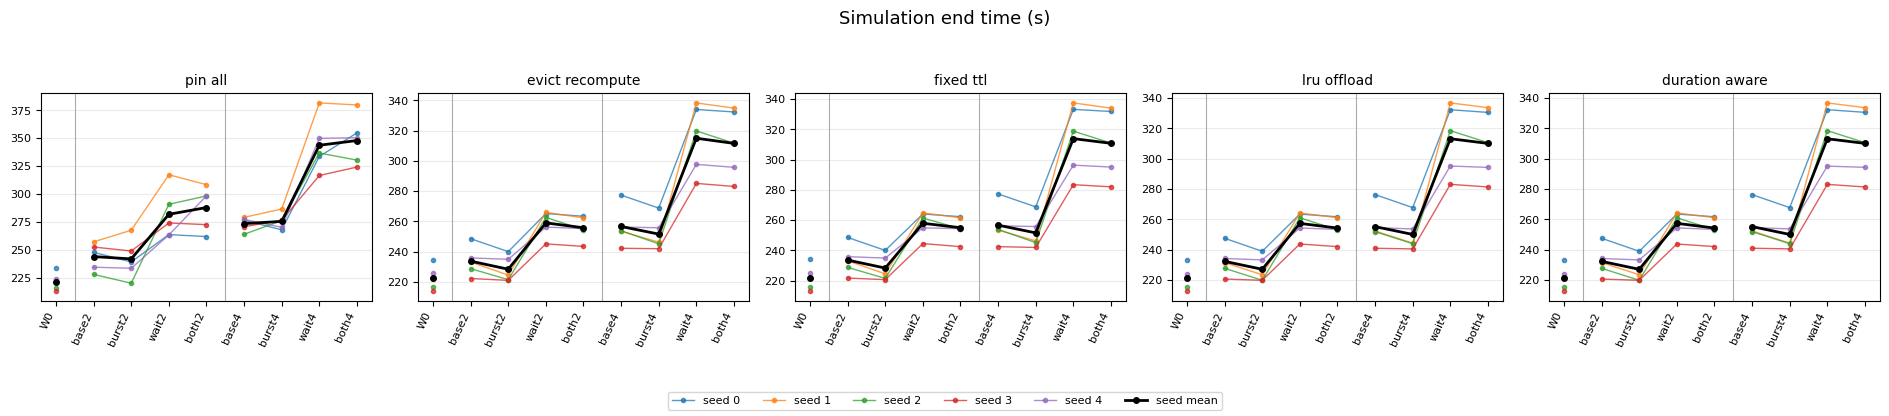

In [9]:
from matplotlib.colors import ListedColormap

load_order = [item['load'] for item in manifest['conditions']]
policy_order = list(manifest['policies'])
seed_order = list(manifest['seeds'])
x = list(range(len(load_order)))
short_labels = ['W0', 'base2', 'burst2', 'wait2', 'both2',
                'base4', 'burst4', 'wait4', 'both4']
seed_colors = plt.get_cmap('tab10').colors[:len(seed_order)]
plot_data = all_results.copy()

# (결과 컬럼, 그래프 제목, 단위 변환 계수)
metric_groups = {
    'SLO 지표와 W0 대비 배율': [
        ('normal_p95_ttft_ms', 'Normal P95 TTFT (ms)', 1),
        ('normal_reject_rate_pct', 'Normal reject rate (%)', 1),
        ('peak_kv_occupancy_pct', 'Peak GPU KV (%)', 1),
        ('ttft_ratio_vs_policy_w0', 'TTFT / same-policy W0', 1),
    ],
    '응답 지연과 작업 완료': [
        ('normal_p50_ttft_ms', 'Normal P50 TTFT (ms)', 1),
        ('all_p95_ttft_ms', 'All-request P95 TTFT (ms)', 1),
        ('task_completion_mean_ms', 'Mean job completion (s)', 1000),
        ('task_completion_p95_ms', 'P95 job completion (s)', 1000),
        ('stress_p95_completion_ms', 'Stress P95 completion (s)', 1000),
        ('throughput_jobs_per_s', 'Completed jobs / s', 1),
    ],
    'GPU KV 점유': [
        ('mean_kv_occupancy_pct', 'Time-weighted mean GPU KV (%)', 1),
        ('kv_above_90_ms', 'Time above 90% KV (s)', 1000),
        ('kv_above_90_pct_of_time', 'Share of time above 90% KV (%)', 1),
    ],
    'KV 관리 비용': [
        ('eviction_count', 'Evictions', 1),
        ('eviction_per_job', 'Evictions / completed job', 1),
        ('offload_count', 'Offloads', 1),
        ('reload_count', 'Reloads', 1),
        ('transfer_bytes', 'CPU-GPU transfer (GiB)', 2**30),
        ('transfer_gib_per_job', 'Transfer / completed job (GiB)', 1),
        ('recomputed_tokens', 'Recomputed tokens', 1),
        ('recomputed_tokens_per_job', 'Recomputed tokens / completed job', 1),
    ],
    '자원 사용률': [
        ('prefill_busy_pct', 'Prefill busy (%)', 1),
        ('pcie_busy_pct', 'PCIe busy (%)', 1),
    ],
    '요청 수와 실행 길이': [
        ('normal_submitted', 'Normal submitted', 1),
        ('normal_completed', 'Normal completed', 1),
        ('normal_rejected', 'Normal rejected', 1),
        ('completed_jobs', 'Completed jobs', 1),
        ('rejected_jobs', 'Rejected jobs', 1),
        ('stress_submitted_jobs', 'Stress submitted jobs', 1),
        ('stress_completed_jobs', 'Stress completed jobs', 1),
        ('sessions', 'Total sessions', 1),
        ('end_ms', 'Simulation end time (s)', 1000),
    ],
}
plotted = {column for group in metric_groups.values() for column, _, _ in group}
numeric_summary = set(summary.select_dtypes(include='number').columns)
config_fields = {'seed', 'stress_level', 'warmup_ms', 'measurement_end_ms'}
assert numeric_summary - config_fields <= plotted

# 정책마다 seed 행, 워크로드 열인 SLO 통과/실패 히트맵
fig, axes = plt.subplots(1, len(policy_order), figsize=(19, 3.2), constrained_layout=True)
for ax, policy in zip(axes, policy_order):
    grid = (plot_data[plot_data.policy == policy]
            .pivot(index='seed', columns='load', values='all_pass')
            .reindex(index=seed_order, columns=load_order)
            .astype(int))
    ax.imshow(grid, cmap=ListedColormap(['#d96c6c', '#68b879']), vmin=0, vmax=1, aspect='auto')
    ax.set_title(policy.replace('_', ' '))
    ax.set_xticks(x, short_labels, rotation=65, ha='right', fontsize=8)
    ax.set_yticks(range(len(seed_order)), [f'seed {seed}' for seed in seed_order], fontsize=8)
    for row in range(len(seed_order)):
        for col in x:
            ax.text(col, row, 'P' if grid.iloc[row, col] else 'F',
                    ha='center', va='center', fontsize=8, color='black')
fig.suptitle('SLO pass by policy, workload, and seed (P=pass, F=fail)', fontsize=13)
display(fig)
plt.close(fig)

# 한 지표에 5개 정책 패널을 배치하고, 각 패널에 5개 seed와 평균을 그린다.
for group_name, metrics in metric_groups.items():
    display(HTML(f'<h3>{group_name}</h3>'))
    for metric, title, divisor in metrics:
        fig, axes = plt.subplots(1, len(policy_order), figsize=(19, 4.1))
        for ax, policy in zip(axes, policy_order):
            frame = plot_data[plot_data.policy == policy]
            for seed, color in zip(seed_order, seed_colors):
                values = (frame[frame.seed == seed].set_index('load')[metric]
                          .reindex(load_order).astype(float) / divisor)
                for positions in ([0], [1, 2, 3, 4], [5, 6, 7, 8]):
                    ax.plot(positions, values.iloc[positions], color=color,
                            marker='o', markersize=3, linewidth=1, alpha=0.75,
                            label=f'seed {seed}' if positions[0] == 1 else '_nolegend_')
            average = frame.groupby('load')[metric].mean().reindex(load_order) / divisor
            for positions in ([0], [1, 2, 3, 4], [5, 6, 7, 8]):
                ax.plot(positions, average.iloc[positions], color='black',
                        marker='o', markersize=4, linewidth=2,
                        label='seed mean' if positions[0] == 1 else '_nolegend_')
            ax.axvline(0.5, color='#aaa', linewidth=0.8)
            ax.axvline(4.5, color='#aaa', linewidth=0.8)
            ax.set_title(policy.replace('_', ' '), fontsize=10)
            ax.set_xticks(x, short_labels, rotation=65, ha='right', fontsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(axis='y', alpha=0.25)
        handles, labels = axes[0].get_legend_handles_labels()
        fig.suptitle(title, fontsize=13)
        fig.legend(handles, labels, loc='lower center', ncol=6, fontsize=8)
        fig.tight_layout(rect=(0, 0.12, 1, 0.94))
        display(fig)
        plt.close(fig)

## 9. 결과에서 얻을 수 있는 인사이트와 프로젝트 방향

이 프로젝트의 연구 질문을 **“도구를 기다리는 Agent 세션의 KV를 언제 유지·이동·삭제해야 일반 요청의 응답 품질을 지키면서 재계산·전송 부담을 줄일 수 있는가?”**로 두고 결과를 읽는다. 이 절의 근거는 이 노트북의 `week7_180s_stress02.json`와 225회 결과다. 아래 표는 원본 CSV를 다시 대조해 만들었으며 기존 SLO 정의를 유지한다. 뒤의 연구 방향은 관측 결과에서 도출한 가설이며, 새 정책의 성능을 입증한 결과는 아니다.

In [10]:
# 원본 CSV의 지표와 seed별 SLO를 다시 대조하고, 인사이트의 근거를 모은다.
import numpy as np

insight_loads = ['w0_1x', 'both_2x', 'both_4x']
insight_rows = []
failure_rows = []
for load in insight_loads:
    for policy in manifest['policies']:
        raw = summary[(summary['load'] == load) & (summary['policy'] == policy)]
        comp = comparison[(comparison['load'] == load) & (comparison['policy'] == policy)].iloc[0]
        seed_slo = slo[(slo['load'] == load) & (slo['policy'] == policy)]
        assert len(raw) == len(seed_slo) == 5
        for metric in ['normal_p95_ttft_ms', 'normal_reject_rate_pct',
                       'peak_kv_occupancy_pct', 'kv_above_90_pct_of_time',
                       'recomputed_tokens', 'transfer_bytes']:
            assert np.isclose(raw[metric].mean(), comp[f'{metric}_mean'])
        baseline = summary[(summary['load'] == 'w0_1x') & (summary['policy'] == policy)].set_index('seed')
        paired = raw.set_index('seed').sort_index()
        ttft_ok = paired.normal_p95_ttft_ms / baseline.normal_p95_ttft_ms <= 3
        reject_ok = paired.normal_reject_rate_pct <= 10
        peak_ok = paired.peak_kv_occupancy_pct <= 90
        combined_ok = ttft_ok & reject_ok & peak_ok
        assert combined_ok.to_dict() == seed_slo.set_index('seed').all_pass.to_dict()
        insight_rows.append({
            'condition': load, 'policy': policy, 'pass_n_of_5': int(combined_ok.sum()),
            'normal_P95_ms': raw.normal_p95_ttft_ms.mean(),
            'normal_reject_pct': raw.normal_reject_rate_pct.mean(),
            'mean_of_peak_pct': raw.peak_kv_occupancy_pct.mean(),
            'time_above90_pct': raw.kv_above_90_pct_of_time.mean(),
            'recomputed_tokens_full_run': raw.recomputed_tokens.mean(),
            'transfer_GiB_full_run': raw.transfer_bytes.mean() / 2**30,
        })
        failure_rows.append({
            'condition': load, 'policy': policy,
            'TTFT_failed_seeds': int((~ttft_ok).sum()),
            'reject_failed_seeds': int((~reject_ok).sum()),
            'peak_failed_seeds': int((~peak_ok).sum()),
        })

print('핵심 지표: 각 seed의 지표를 평균한 값이며, pass는 seed별 세 조건을 모두 만족한 횟수다.')
display(pd.DataFrame(insight_rows).round(2))
print('실패 원인은 중복될 수 있다. 예: 한 seed가 TTFT와 Peak를 동시에 실패할 수 있다.')
display(pd.DataFrame(failure_rows))

coverage_rows = []
for load in ['both_2x', 'both_4x']:
    frames = []
    for run in summary[(summary['policy'] == 'duration_aware') & (summary['load'] == load)].itertuples():
        frames.append(pd.read_csv(OUTPUT / 'runs' / run.run_id / 'events.csv'))
    event_frame = pd.concat(frames, ignore_index=True)
    idle_decisions = event_frame.loc[event_frame.event == 'TOOL_START', 'detail'].str.extract(r'decision=(\w+)')[0].value_counts()
    pressure = event_frame[(event_frame.event == 'OFFLOAD_START') &
                           event_frame.detail.fillna('').str.contains('reason=pressure')]
    coverage_rows.append({
        'condition': load, 'idle_KEEP': int(idle_decisions.get('keep', 0)),
        'idle_OFFLOAD': int(idle_decisions.get('offload', 0)),
        'idle_EVICT': int(idle_decisions.get('evict', 0)),
        'pressure_OFFLOAD_starts': len(pressure),
        'all_EVICT_events': int((event_frame.event == 'EVICT').sum()),
    })
print('Duration-Aware 동작 범위: idle 진입 결정과 메모리 부족 시 동작을 구분한다. 5개 seed 합계다.')
display(pd.DataFrame(coverage_rows))

핵심 지표: 각 seed의 지표를 평균한 값이며, pass는 seed별 세 조건을 모두 만족한 횟수다.


,condition,policy,pass_n_of_5,normal_P95_ms,normal_reject_pct,mean_of_peak_pct,time_above90_pct,recomputed_tokens_full_run,transfer_GiB_full_run
0,w0_1x,pin_all,3,643.45,0.00,85.62,3.95,0.0,0.00
1,w0_1x,evict_recompute,4,733.79,0.00,82.47,0.27,361485.8,0.00
2,w0_1x,fixed_ttl,3,622.10,0.00,86.11,3.35,167502.0,0.00
3,w0_1x,lru_offload,3,243.65,0.00,85.56,1.79,0.0,2.51
4,w0_1x,duration_aware,4,242.11,0.00,82.27,0.12,0.0,6.68
5,both_2x,pin_all,0,24168.94,7.33,99.99,56.02,0.0,0.00
6,both_2x,evict_recompute,4,811.39,0.00,84.55,0.06,361485.8,0.00
7,both_2x,fixed_ttl,2,515.90,0.00,91.47,1.33,162194.4,0.00
8,both_2x,lru_offload,0,305.65,0.00,99.72,19.93,0.0,13.56
9,both_2x,duration_aware,0,304.77,0.00,99.46,3.21,0.0,31.74


실패 원인은 중복될 수 있다. 예: 한 seed가 TTFT와 Peak를 동시에 실패할 수 있다.


,condition,policy,TTFT_failed_seeds,reject_failed_seeds,peak_failed_seeds
0,w0_1x,pin_all,0,0,2
1,w0_1x,evict_recompute,0,0,1
2,w0_1x,fixed_ttl,0,0,2
3,w0_1x,lru_offload,0,0,2
4,w0_1x,duration_aware,0,0,1
5,both_2x,pin_all,5,3,5
6,both_2x,evict_recompute,0,0,1
7,both_2x,fixed_ttl,0,0,3
8,both_2x,lru_offload,0,0,5
9,both_2x,duration_aware,0,0,5


Duration-Aware 동작 범위: idle 진입 결정과 메모리 부족 시 동작을 구분한다. 5개 seed 합계다.


,condition,idle_KEEP,idle_OFFLOAD,idle_EVICT,pressure_OFFLOAD_starts,all_EVICT_events
0,both_2x,329,187,0,25,0
1,both_4x,287,229,0,19,0


### 이 설정의 결과에서 읽을 수 있는 것

1. **180초·0.2의 W0는 일부 seed에서 이미 경계에 있다.** W0의 전체 통과는 Pin-All·Fixed TTL·LRU가 각각 3/5, Evict/Recompute·Duration-Aware가 각각 4/5다. normal 거절은 없지만 순간 Peak가 걸린다. 따라서 모든 W2 실패를 추가 요인 탓으로만 설명할 수 없고, 장시간 기준 부하의 안전 영역도 먼저 확인해야 한다. 180초를 돌렸다는 사실만으로 정상 상태나 장시간 안정성이 입증되지는 않는다.

2. **W2에서 Pin-All의 악화는 순간적인 Peak만의 문제가 아니다.** W2 4x에서 평균 점유율은 89.78%, 90% 초과 비율은 79.13%, normal P95는 29.81초, 거절률은 17.61%다. KV를 계속 보유하면 장시간 과밀이 일반 요청의 입장 대기와 거절로 이어진다는 현상을 재현했다.

3. **현재 유력한 개선 지점은 낮은 지연을 유지하면서 순간 과밀을 줄이는 것이다.** W2 4x의 Duration-Aware는 normal P95 309.8ms·거절률 0%지만 평균 Peak 98.68%로 0/5다. Evict/Recompute는 P95 691.0ms·Peak 80.91%로 4/5다. 다만 전자는 run당 전송 약 37.13GiB, 후자는 재계산 약 361,486토큰을 쓴다. 한 정책의 무조건적인 우승보다, 이 교환 관계를 설명하고 개선하는 것이 프로젝트에 맞다.

4. **좋은 도구 대기 예측만으로 여유 공간 목표가 보장되지는 않는다.** Duration-Aware는 W1 base 2x부터 평균 Peak 96.26%이며 0/5다. 최악 seed 1의 W2 4x Peak는 130.617초의 ADMIT에서 99.96%다. 앞선 offload가 끝난 뒤에도 새 입장으로 다시 거의 가득 차고, 추가 pressure offload가 뒤따른다. 이 사례는 “도구가 오래 걸리는지 아는가”와 “큰 KV를 받아들이기 전에 여유를 확보하는가”를 별도로 확인해야 함을 보여준다.

5. **3가지 행동의 비용 판단은 아직 충분히 시험하지 못했다.** W2 2x의 idle KEEP/OFFLOAD는 329/187회, 4x는 287/229회이며 EVICT 이벤트는 0회다. 따라서 이번 결과는 대기시간을 아는 참조 정책의 KEEP/OFFLOAD 동작을 주로 평가한다. 재계산 추정값은 로그에 있지만 현재 분기에서 전송과 재계산 비용을 직접 최적화하는 데 쓰이지 않는다.

### 도구 대기에 가려진 모델·스케줄링 시간을 함께 보기

위 그래프의 stress 작업 완료 P95에는 도구를 기다리는 시간이 들어간다. 다음 표는 **완료한 각 작업의 전체 시간에서 그 작업의 도구 대기 합을 먼저 뺀 뒤**, run별 P95와 seed 평균을 구한다. 이 값에는 decode·prefill·입장 대기·재계산·reload가 함께 포함되므로 KV 정책만의 순수한 비용은 아니다. 완료 수가 적은 정책에는 살아남은 작업만 남는 편향이 있으므로, 표의 완료 수와 normal 거절을 반드시 함께 본다.

In [11]:
# 보조 진단: 완료한 stress 작업마다 실제 도구 대기 합을 뺀 뒤 P95를 구한다.
# 두 P95를 빼는 방식이 아니다. 이 값에도 decode, prefill, 입장 대기, 복구가 포함된다.
from kvbench.metrics import percentile

non_tool_rows = []
trace_jobs_cache = {}
for run in summary[summary['load'].isin(['w0_1x', 'both_4x'])].itertuples():
    if run.trace not in trace_jobs_cache:
        trace = pd.read_json(OUTPUT / 'traces' / run.trace, lines=True)
        stress_trace = trace[trace.request_class == 'stress']
        trace_jobs_cache[run.trace] = stress_trace.groupby('session_id').agg(
            initial_arrival_ms=('session_arrival_ms', 'first'),
            tool_wait_sum_ms=('tool_duration_ms', 'sum'),
            expected_turns=('expected_turns', 'first'),
        )
    jobs = trace_jobs_cache[run.trace]
    requests = pd.read_csv(OUTPUT / 'runs' / run.run_id / 'requests.csv')
    values = []
    for sid, turns in requests[requests.request_class == 'stress'].groupby('session_id'):
        job = jobs.loc[sid]
        if job.initial_arrival_ms < manifest['workload_config']['warmup_ms']:
            continue
        if len(turns) != int(job.expected_turns) or not (turns.outcome == 'completed').all():
            continue
        assert turns.turn_id.nunique() == int(job.expected_turns)
        elapsed = turns.complete_ms.max() - job.initial_arrival_ms
        non_tool = elapsed - job.tool_wait_sum_ms
        assert non_tool >= -1e-6
        values.append(max(non_tool, 0))
    assert len(values) == run.stress_completed_jobs
    non_tool_rows.append({
        'condition': run.load, 'policy': run.policy, 'seed': run.seed,
        'completed_stress_jobs': len(values),
        'non_tool_stress_P95_ms': percentile(values, 95),
    })

non_tool = pd.DataFrame(non_tool_rows)
non_tool_table = non_tool.groupby(['condition', 'policy']).agg(
    mean_completed_stress_jobs=('completed_stress_jobs', 'mean'),
    mean_of_non_tool_P95_s=('non_tool_stress_P95_ms', lambda values: values.mean() / 1000),
)
display(non_tool_table.round(3))
print('완료 작업만의 P95다. 완료 수가 다른 정책은 거절·중단으로 표본이 달라지므로 함께 비교해야 한다.')

mean_completed_stress_jobs  mean_of_non_tool_P95_s
condition policy                                                             
both_4x   duration_aware                         32.6                  16.434
          evict_recompute                        32.6                  18.551
          fixed_ttl                              32.6                  18.023
          lru_offload                            32.6                  16.445
          pin_all                                15.4                  99.622
w0_1x     duration_aware                         32.6                  16.275
          evict_recompute                        32.6                  18.549
          fixed_ttl                              32.6                  17.566
          lru_offload                            32.6                  16.273
          pin_all                                32.6                  16.901

완료 작업만의 P95다. 완료 수가 다른 정책은 거절·중단으로 표본이 달라지므로 함께 비교해야 한다.


### 프로젝트의 다음 판단과 실험 순서

이 설정은 **실행 기간을 늘렸을 때의 부하 누적과 Peak 실패를 점검하는 주 실험 후보**다. 다만 W0부터 모든 seed가 안전한 설정은 아니므로, 이를 “완전히 안전한 정상 운영”이라고 부르지는 않는다.

다음 분석의 우선순위는 Peak 당시의 active·idle·전송 중 KV와 입장 대기열을 기록해, 회수할 idle KV가 있었는지와 전송이 늦었는지를 구분하는 것이다. 그 뒤 도착률·기간·GPU 풀 크기의 민감도를 같은 정책·같은 평가 기준으로 비교한다. 정책을 보완한다면 대기시간 기반 판단과 메모리 여유 확보가 각각 어떤 효과를 냈는지 분리해 검증해야 한다. 현재 정책 구현은 이 노트북에서 바꾸지 않는다.

이 추가 진단에서 W2 4x의 도구 대기 제외 P95는 Duration-Aware가 약 16.43초, Evict/Recompute가 약 18.55초다. 원래 stress 완료시간만 보면 가려질 수 있는 차이다. 이 값도 생성 시간 전체를 포함하므로, 정책의 직접 비용을 확인하려면 이후 입장 대기·prefill 대기·복구 시간을 따로 분해하는 편이 좋다.

다음 정책 구현 전에 우선 확인할 사항은 세 가지다.

1. **평가 목표를 고정한다.** 기존 SLO를 보존하고 서비스 요구에 근거한 절대 normal TTFT 목표, stress 완료율, 메모리 여유 목표를 정한다. Peak를 엄격히 제한할지, 초과 지속시간도 운영 목표로 둘지는 실험 전에 결정한다. 결과를 보고 유리한 기준으로 바꾸지 않는다.
2. **원인과 정책의 선택 범위를 검증한다.** Peak의 KV 소유 상태, 전송 대기열, 입장 대기, 실행된 KEEP/OFFLOAD/EVICT를 확인한다. 평균을 맞춘 대기 분포, 더 느린 PCIe·작은 CPU 풀, 대기 예측 오차 등을 별도 조건으로 두어 지금 거의 평가되지 않은 선택 구간도 확인한다. 파라미터를 고른 seed와 최종 평가 seed를 구분하고, 다섯 seed의 통과율을 일반적인 확률로 단정하지 않는다.
3. **시뮬레이터와 실제 실행 사이를 연결한다.** 실제 대상 환경에서 prefill·decode·KV 크기·전송 속도를 보정하고 민감도를 본다. 현재 모델은 고정 decode 속도와 단일 FIFO prefill·PCIe를 가정하므로, 절대 ms나 GiB 수치를 실제 GPU 성능으로 주장할 수 없다.

현재 단계의 기여는 **통제된 입력에서 정책의 지연·메모리·복구 비용 차이를 재현하고, 개선이 필요한 실패 원인을 좁히는 것**이다. 이후 개선안을 평가할 때도 한 통과율의 상승뿐 아니라, 같은 서비스 목표에서 무엇을 줄이고 어떤 비용을 더 썼는지를 설명해야 한다.

### 이 인사이트를 읽을 때 고정할 지표 정의

- 표의 TTFT와 Peak는 **seed별 P95 또는 Peak를 구한 뒤 5개 seed에서 평균**한 값이다. 전체 요청을 합쳐 구한 P95가 아니며, 평균 Peak가 90% 미만이어도 일부 seed는 실패할 수 있다.
- 현행 SLO는 정책별 자기 W0 대비 TTFT 비율을 쓴다. 빠른 W0를 가진 정책에 상대 기준이 더 까다로울 수 있고, 느린 W0는 큰 지연도 통과시킬 수 있다. 절대 TTFT·거절률·작업 완료 수를 함께 본다. 실패한 요청은 완료 요청 TTFT 표본에 들어가지 않는다.
- Peak는 warmup 이후 **drain 종료까지**, 평균 점유율·90% 초과 비율은 **입력 기간 끝까지**다. 전송량·재계산·evict/offload 횟수는 **warmup과 drain을 포함한 전체 run 누계**다. 현재 per-job 비용은 이 누계를 warmup 이후 완료 수로 나눈 값이므로, 엄밀한 효율 비교 전에는 분자·분모 구간을 맞춰야 한다.
- 90%는 평가에서 정한 여유 공간 목표다. 현재 입장 로직은 실제 풀 용량인 100% 안에서 할당하며, 모든 정책이 90% 상한을 유지하도록 구현된 것은 아니다. 실패를 없애려고 사후에 기준을 바꾸지 않고, Peak와 초과 지속시간을 함께 보고한다.
- `base→burst`는 도착 집중의 대비다. `base→wait`에는 교대 패턴과 평균 대기 증가가 함께 들어간다. 2x보다 4x가 좋은 지표가 있어도, 대기 연장으로 복귀 시각이 분산되거나 TTL이 더 많이 만료된 결과일 수 있다. 현 결과만으로 단조 관계나 순수 변동성 효과를 주장하지 않는다.